pip install numpy matplotlib scipy scikit-learn

pip install --upgrade pip

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from sklearn.linear_model import LinearRegression

C:\Users\congc\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
nx, ny = 50, 50

In [3]:
# pollution field
u = np.zeros((nx, ny))
u[10, 10] = 100
u[35, 20] = 80
u[25, 40] = 60

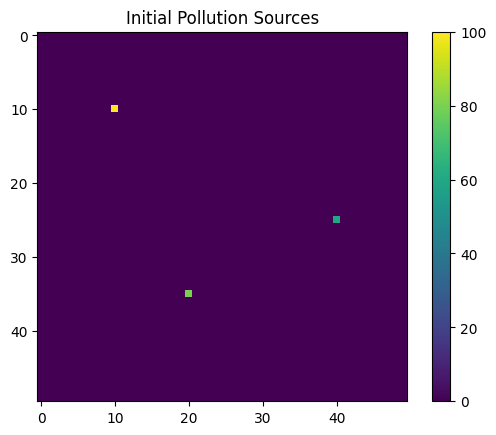

In [4]:
plt.imshow(u)
plt.colorbar()
plt.title("Initial Pollution Sources")
plt.show()

In [5]:
D = 0.1      # diffusion strength
vx = 1.0     # wind in x direction
vy = 0.3     # wind in y direction

dt = 0.1
n_steps = 100

In [6]:
for t in range(n_steps):

    # diffusion
    laplacian = (
        np.roll(u, 1, axis=0) +
        np.roll(u, -1, axis=0) +
        np.roll(u, 1, axis=1) +
        np.roll(u, -1, axis=1) -
        4 * u
    )

    # advection (wind transport)
    advect_x = np.roll(u, 1, axis=0) - u
    advect_y = np.roll(u, 1, axis=1) - u

    # update pollution field
    u = u + dt * (
        D * laplacian
        - vx * advect_x
        - vy * advect_y
    )

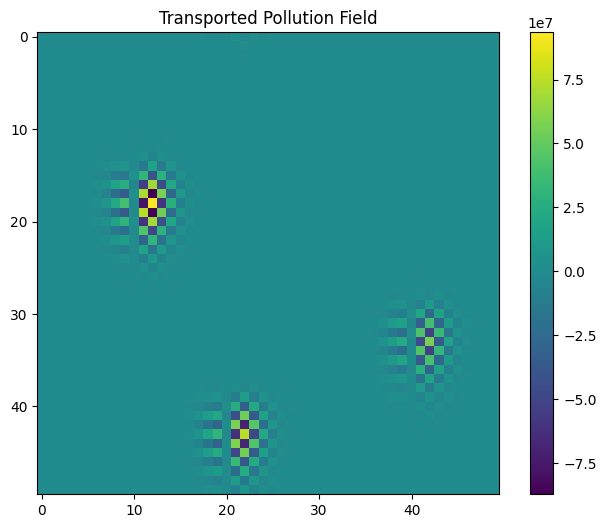

In [7]:
plt.figure(figsize=(8,6))
plt.imshow(u)
plt.colorbar()
plt.title("Transported Pollution Field")
plt.show()

In [8]:
A_spill_true = u.copy()

In [9]:
A_local = np.random.normal(size=(nx, ny))

In [10]:
beta1 = 1.0
beta2 = 2.0
#direct effect = 1
#spillover effect = 2
epsilon = np.random.normal(scale=0.5, size=(nx, ny))

Y = (
    beta1 * A_local +
    beta2 * A_spill_true +
    epsilon
)

In [11]:
A_spill_gaussian = gaussian_filter(A_local, sigma=3)

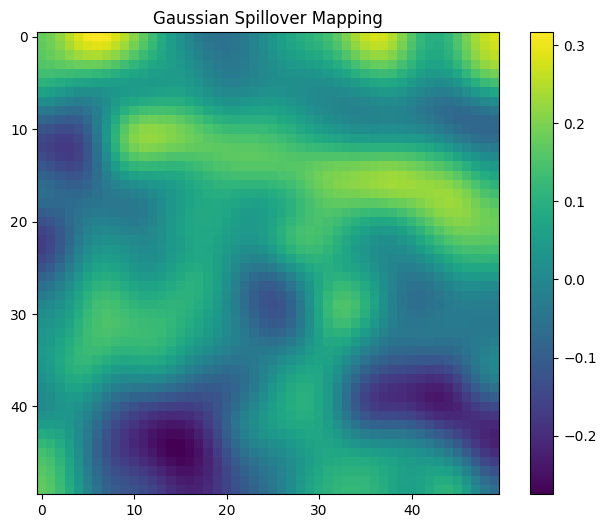

In [12]:
plt.figure(figsize=(8,6))
plt.imshow(A_spill_gaussian)
plt.colorbar()
plt.title("Gaussian Spillover Mapping")
plt.show()

In [13]:
X = np.column_stack([
    A_local.flatten(),
    A_spill_gaussian.flatten()
])

y = Y.flatten()

model = LinearRegression()
model.fit(X, y)

print("Estimated coefficients:")
print(model.coef_)

Estimated coefficients:
[ 333490.04707277 -577216.87709303]


In [14]:
beta1 = 1.0
beta2 = 2.0

In [15]:
X_true = np.column_stack([
    A_local.flatten(),
    A_spill_true.flatten()
])

model_true = LinearRegression()
model_true.fit(X_true, y)

print("Estimated coefficients using true spillover:")
print(model_true.coef_)

Estimated coefficients using true spillover:
[1.0030551 2.       ]


In [16]:
print(
    np.corrcoef(
        A_local.flatten(),
        A_spill_gaussian.flatten()
    )
)

[[1.         0.18473727]
 [0.18473727 1.        ]]


In [17]:
print(
    np.corrcoef(
        A_local.flatten(),
        A_spill_true.flatten()
    )
)

[[1.         0.01816634]
 [0.01816634 1.        ]]


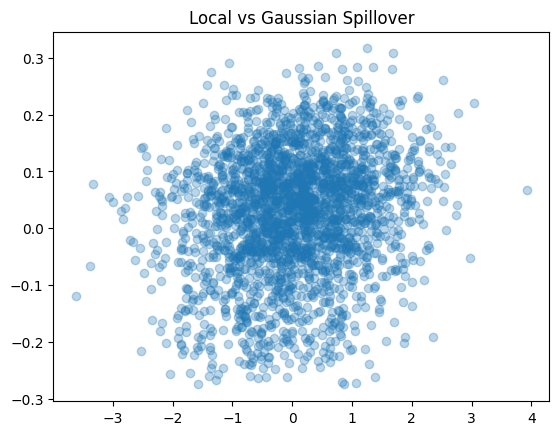

In [18]:
plt.scatter(
    A_local.flatten(),
    A_spill_gaussian.flatten(),
    alpha=0.3
)

plt.title("Local vs Gaussian Spillover")

plt.show()

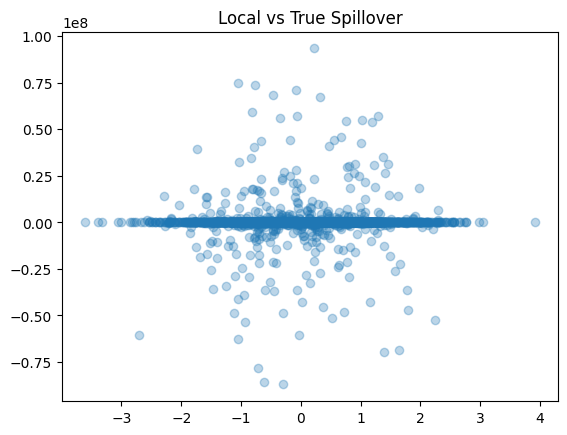

In [19]:
plt.scatter(
    A_local.flatten(),
    A_spill_true.flatten(),
    alpha=0.3
)

plt.title("Local vs True Spillover")

plt.show()

In [20]:
from numpy.linalg import cond

X_gaussian = np.column_stack([
    A_local.flatten(),
    A_spill_gaussian.flatten()
])

X_true = np.column_stack([
    A_local.flatten(),
    A_spill_true.flatten()
])

print("Condition number (Gaussian):")
print(cond(X_gaussian))

print("Condition number (True):")
print(cond(X_true))

Condition number (Gaussian):
8.991878809049108
Condition number (True):
8854838.570563124



weak_transport

TRUE MODEL COEFFICIENTS
[1.01816314 2.00008407]

strong_transport

TRUE MODEL COEFFICIENTS
[-1.7498832e-15  2.0000000e+00]

gaussian_like_transport

TRUE MODEL COEFFICIENTS
[0.99096753 1.9905013 ]

directional_transport

TRUE MODEL COEFFICIENTS
[-6.85999398e-22  2.00000000e+00]

FINAL RESULTS
                       case  sigma  corr_local_gaussian  condition_number  \
0            weak_transport      1             0.575908          4.219957   
1            weak_transport      2             0.302196          6.940163   
2            weak_transport      3             0.203776         10.221868   
3            weak_transport      5             0.121829         17.358091   
4            weak_transport      8             0.071604         27.627843   
5            weak_transport     10             0.056309         33.930907   
6          strong_transport      1             0.575908          4.219957   
7          strong_transport      2             0.302196          6.940163

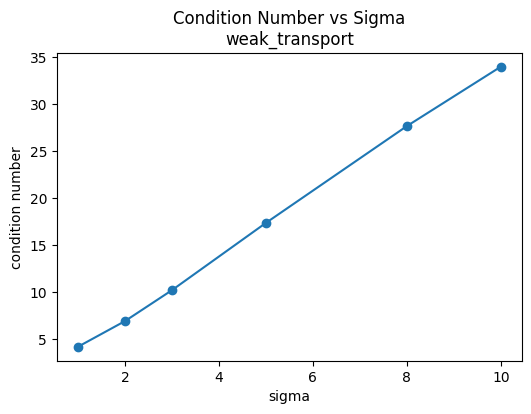

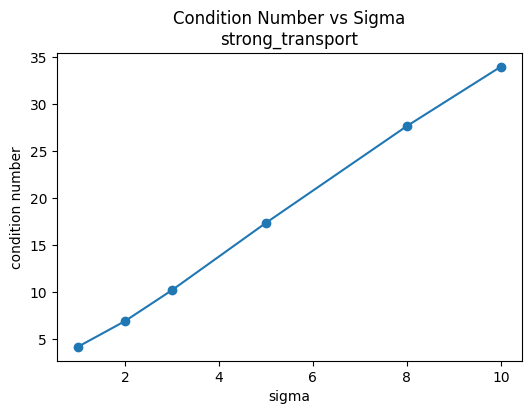

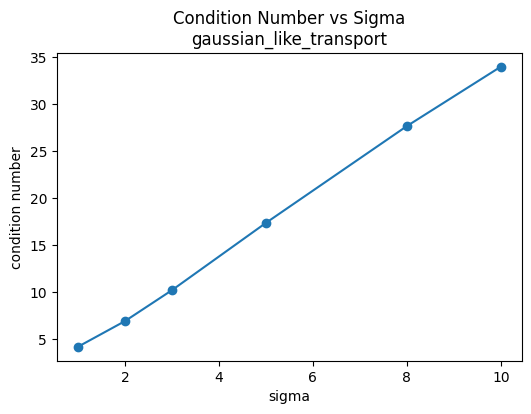

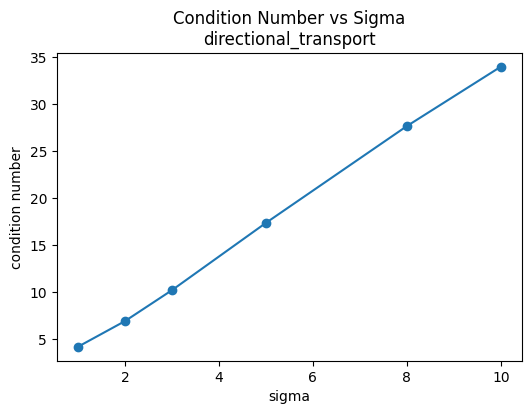

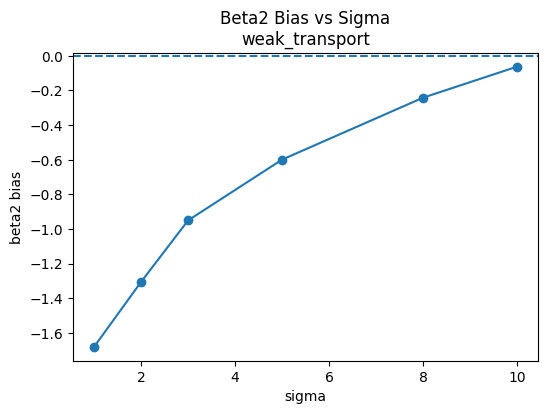

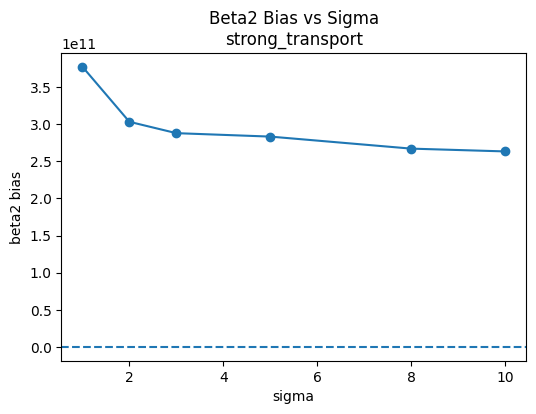

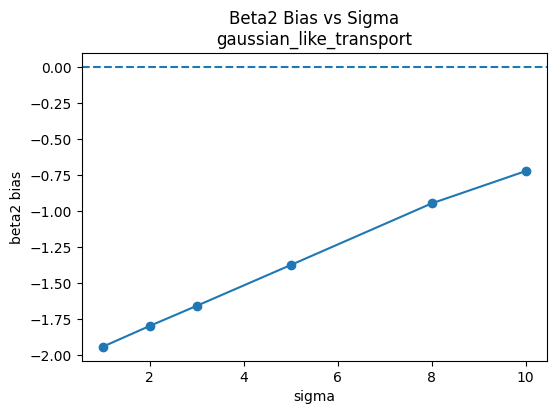

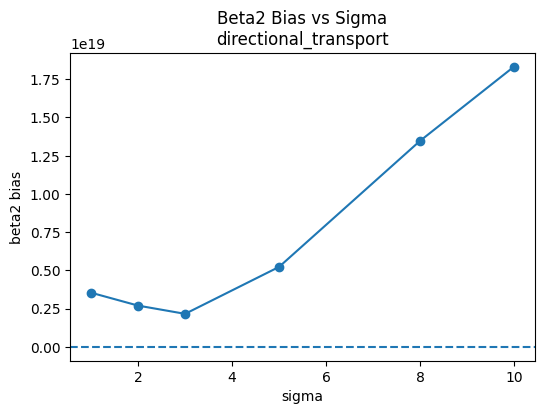

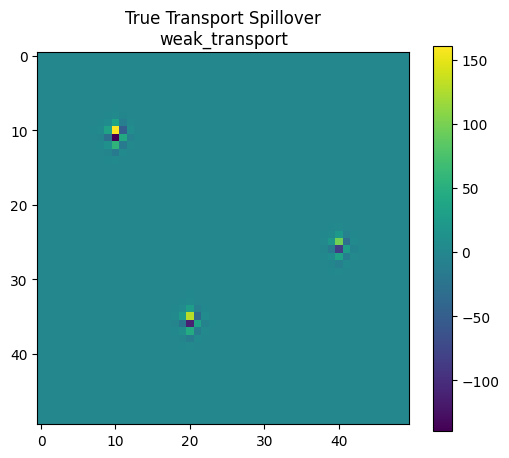

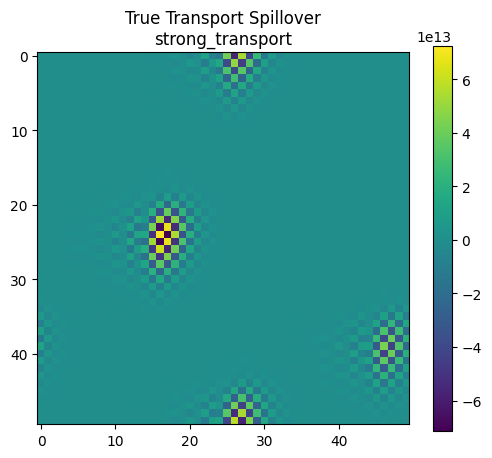

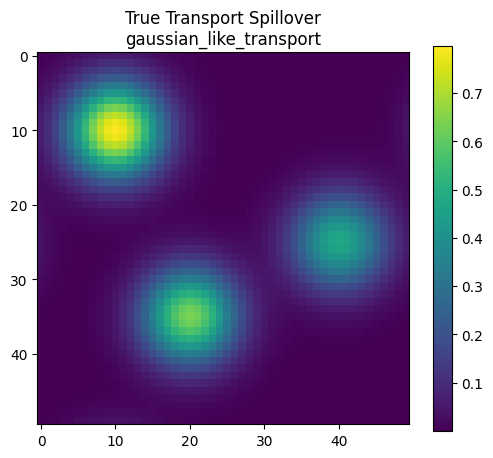

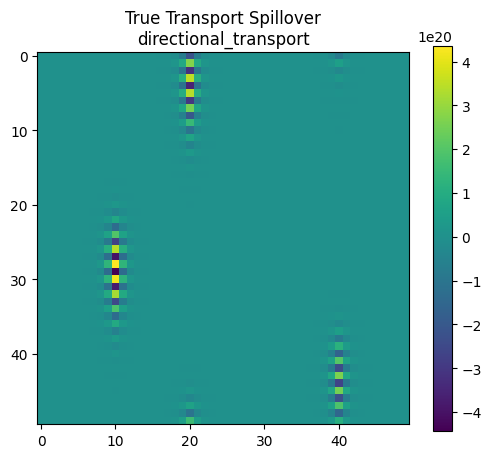

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter
from sklearn.linear_model import LinearRegression
from numpy.linalg import cond

 
nx = 50
ny = 50

beta1_true = 1.0
beta2_true = 2.0

np.random.seed(123)

 

A_local = np.random.normal(
    loc=0,
    scale=1,
    size=(nx, ny)
)

 

u0 = np.zeros((nx, ny))

u0[10,10] = 100
u0[35,20] = 80
u0[25,40] = 60

 

def simulate_transport(
    u_init,
    D=0.1,
    vx=1.0,
    vy=0.3,
    dt=0.1,
    n_steps=100
):

    u = u_init.copy()

    for t in range(n_steps):

        # diffusion
        laplacian = (
            np.roll(u,1,axis=0)
            + np.roll(u,-1,axis=0)
            + np.roll(u,1,axis=1)
            + np.roll(u,-1,axis=1)
            - 4*u
        )

        # advection
        advect_x = np.roll(u,1,axis=0) - u
        advect_y = np.roll(u,1,axis=1) - u

        # update
        u = u + dt * (
            D * laplacian
            - vx * advect_x
            - vy * advect_y
        )

    return u

 
cases = {

 

    "weak_transport": {
        "D": 0.02,
        "vx": 0.1,
        "vy": 0.05
    },

 

    "strong_transport": {
        "D": 0.3,
        "vx": 2.0,
        "vy": 1.0
    },

 

    "gaussian_like_transport": {
        "D": 1.0,
        "vx": 0.0,
        "vy": 0.0
    },
 

    "directional_transport": {
        "D": 0.05,
        "vx": 3.0,
        "vy": 0.0
    }
}

 
sigmas = [1,2,3,5,8,10]

 

results = []

 

for case_name, params in cases.items():

 

 

    A_spill_true = simulate_transport(
        u_init=u0,
        D=params["D"],
        vx=params["vx"],
        vy=params["vy"]
    )

  

    epsilon = np.random.normal(
        scale=0.5,
        size=(nx, ny)
    )

    Y = (
        beta1_true * A_local
        + beta2_true * A_spill_true
        + epsilon
    )

    y = Y.flatten()

 

    X_true = np.column_stack([
        A_local.flatten(),
        A_spill_true.flatten()
    ])

    model_true = LinearRegression()
    model_true.fit(X_true, y)

    print("\nTRUE MODEL COEFFICIENTS")
    print(model_true.coef_)

 

    for sigma in sigmas:

  

        A_spill_gaussian = gaussian_filter(
            A_local,
            sigma=sigma
        )

     

        X_gaussian = np.column_stack([
            A_local.flatten(),
            A_spill_gaussian.flatten()
        ])

      

        model_gaussian = LinearRegression()

        model_gaussian.fit(X_gaussian, y)

        beta1_hat = model_gaussian.coef_[0]
        beta2_hat = model_gaussian.coef_[1]

 

        corr = np.corrcoef(
            A_local.flatten(),
            A_spill_gaussian.flatten()
        )[0,1]

 

        condition_num = cond(X_gaussian)

       

        beta1_bias = beta1_hat - beta1_true
        beta2_bias = beta2_hat - beta2_true

   

        results.append({

            "case": case_name,

            "sigma": sigma,

            "corr_local_gaussian": corr,

            "condition_number": condition_num,

            "beta1_hat": beta1_hat,

            "beta2_hat": beta2_hat,

            "beta1_bias": beta1_bias,

            "beta2_bias": beta2_bias
        })

 
results_df = pd.DataFrame(results)

 

print(results_df)

 

for case_name in cases.keys():

    subset = results_df[
        results_df["case"] == case_name
    ]

    plt.figure(figsize=(6,4))

    plt.plot(
        subset["sigma"],
        subset["condition_number"],
        marker='o'
    )

    plt.title(
        f"Condition Number vs Sigma\n{case_name}"
    )

    plt.xlabel("sigma")
    plt.ylabel("condition number")

    plt.show()
 

for case_name in cases.keys():

    subset = results_df[
        results_df["case"] == case_name
    ]

    plt.figure(figsize=(6,4))

    plt.plot(
        subset["sigma"],
        subset["beta2_bias"],
        marker='o'
    )

    plt.axhline(
        0,
        linestyle='--'
    )

    plt.title(
        f"Beta2 Bias vs Sigma\n{case_name}"
    )

    plt.xlabel("sigma")
    plt.ylabel("beta2 bias")

    plt.show()

 

for case_name, params in cases.items():

    A_spill_true = simulate_transport(
        u_init=u0,
        D=params["D"],
        vx=params["vx"],
        vy=params["vy"]
    )

    plt.figure(figsize=(6,5))

    plt.imshow(A_spill_true)

    plt.colorbar()

    plt.title(
        f"True Transport Spillover\n{case_name}"
    )

    plt.show()

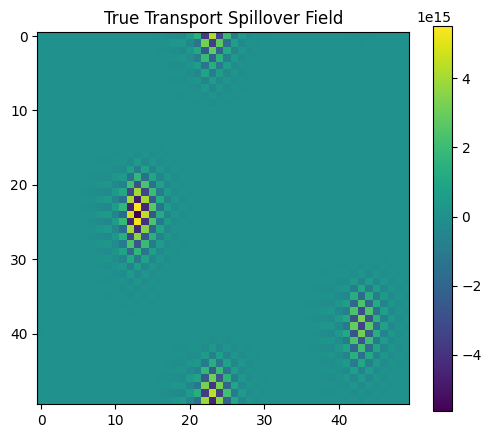

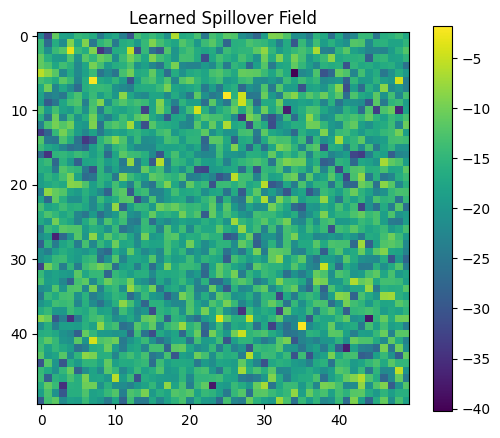


RMSE TRANSPORT RECOVERY
640039290424561.5

GAUSSIAN REGRESSION
[ 1.11124997e+13 -2.09461756e+13]

LEARNED TRANSPORT REGRESSION
[9.00405802e+12 3.73222913e+12]

TRUE MODEL
[2.72835198e-17 2.00000000e+00]

FINAL RESULTS
               model     beta1_hat     beta2_hat
0           gaussian  1.111250e+13 -2.094618e+13
1  learned_transport  9.004058e+12  3.732229e+12
2     true_transport  2.728352e-17  2.000000e+00

TRUE VALUES
beta1 = 1.0
beta2 = 2.0

CORRELATIONS
Gaussian vs True = -4.579670412312587e-05
Learned vs True = 0.01625087844280365


In [ ]:
 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter

from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error
 

nx = 50
ny = 50

 

u0 = np.zeros((nx, ny))

u0[10,10] = 100
u0[35,20] = 80
u0[25,40] = 60

 

# wind x-direction
wind_x = np.ones((nx, ny)) * 2.0

# wind y-direction
wind_y = np.ones((nx, ny)) * 0.5

# temperature
temperature = np.random.normal(
    loc=25,
    scale=3,
    size=(nx, ny)
)

# humidity
humidity = np.random.normal(
    loc=60,
    scale=10,
    size=(nx, ny)
)

 

def simulate_transport(
    u_init,
    wind_x,
    wind_y,
    D=0.1,
    dt=0.1,
    n_steps=100
):

    u = u_init.copy()

    for t in range(n_steps):

        # diffusion
        laplacian = (
            np.roll(u,1,axis=0)
            + np.roll(u,-1,axis=0)
            + np.roll(u,1,axis=1)
            + np.roll(u,-1,axis=1)
            - 4*u
        )

        # advection
        advect_x = np.roll(u,1,axis=0) - u
        advect_y = np.roll(u,1,axis=1) - u

        # update
        u = u + dt * (
            D * laplacian
            - wind_x * advect_x
            - wind_y * advect_y
        )

    return u

 

A_spill_true = simulate_transport(
    u_init=u0,
    wind_x=wind_x,
    wind_y=wind_y
)

 

plt.figure(figsize=(6,5))

plt.imshow(A_spill_true)

plt.colorbar()

plt.title("True Transport Spillover Field")

plt.show()

 

A_local = np.random.normal(
    loc=0,
    scale=1,
    size=(nx, ny)
)

 

beta1_true = 1.0
beta2_true = 2.0

epsilon = np.random.normal(
    scale=0.5,
    size=(nx, ny)
)

Y = (
    beta1_true * A_local
    + beta2_true * A_spill_true
    + epsilon
)

 

A_spill_gaussian = gaussian_filter(
    A_local,
    sigma=5
)

 

X_train = np.column_stack([

    A_local.flatten(),

    wind_x.flatten(),

    wind_y.flatten(),

    temperature.flatten(),

    humidity.flatten()

])

y_train = A_spill_true.flatten()

 

nn_model = MLPRegressor(

    hidden_layer_sizes=(64,64),

    activation='relu',

    max_iter=1000,

    random_state=123
)

nn_model.fit(X_train, y_train)

 

A_spill_learned = nn_model.predict(X_train)

A_spill_learned = A_spill_learned.reshape(nx, ny)
 

plt.figure(figsize=(6,5))

plt.imshow(A_spill_learned)

plt.colorbar()

plt.title("Learned Spillover Field")

plt.show()

 

rmse_transport = np.sqrt(

    mean_squared_error(

        A_spill_true.flatten(),

        A_spill_learned.flatten()
    )
)

print("\nRMSE TRANSPORT RECOVERY")
print(rmse_transport)
 
 
X_gaussian = np.column_stack([

    A_local.flatten(),

    A_spill_gaussian.flatten()
])

y = Y.flatten()

model_gaussian = LinearRegression()

model_gaussian.fit(X_gaussian, y)

print("\nGAUSSIAN REGRESSION")

print(model_gaussian.coef_)

 

X_learned = np.column_stack([

    A_local.flatten(),

    A_spill_learned.flatten()
])

model_learned = LinearRegression()

model_learned.fit(X_learned, y)

print("\nLEARNED TRANSPORT REGRESSION")

print(model_learned.coef_)

 

X_true = np.column_stack([

    A_local.flatten(),

    A_spill_true.flatten()
])

model_true = LinearRegression()

model_true.fit(X_true, y)

print("\nTRUE MODEL")

print(model_true.coef_)

 

results = pd.DataFrame({

    "model":[

        "gaussian",

        "learned_transport",

        "true_transport"
    ],

    "beta1_hat":[

        model_gaussian.coef_[0],

        model_learned.coef_[0],

        model_true.coef_[0]
    ],

    "beta2_hat":[

        model_gaussian.coef_[1],

        model_learned.coef_[1],

        model_true.coef_[1]
    ]
})

print("\nFINAL RESULTS")

print(results)

 

print("\nTRUE VALUES")

print("beta1 =", beta1_true)

print("beta2 =", beta2_true)

 

corr_gaussian = np.corrcoef(

    A_spill_true.flatten(),

    A_spill_gaussian.flatten()

)[0,1]

corr_learned = np.corrcoef(

    A_spill_true.flatten(),

    A_spill_learned.flatten()

)[0,1]

print("\nCORRELATIONS")

print("Gaussian vs True =", corr_gaussian)

print("Learned vs True =", corr_learned)

0 data_loss = 4.09650331931924e+29 pde_loss = 0.028410470113158226
500 data_loss = 4.09650331931924e+29 pde_loss = 11110.1083984375
1000 data_loss = 4.09650331931924e+29 pde_loss = 46831.83203125
1500 data_loss = 4.09650331931924e+29 pde_loss = 104849.703125
2000 data_loss = 4.09650331931924e+29 pde_loss = 181212.34375
2500 data_loss = 4.09650331931924e+29 pde_loss = 286175.65625


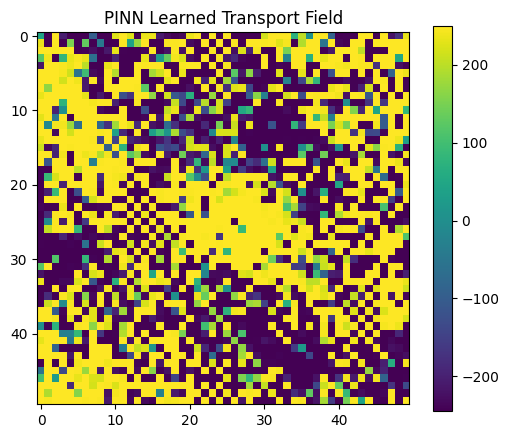


PINN RMSE
640039290424508.1

PINN CAUSAL REGRESSION
[7.23805969e+12 1.28188595e+12]

TRUE VALUES
1.0 2.0


In [ ]:
 

import torch
import torch.nn as nn
import torch.optim as optim
 

nx = 50
ny = 50

# coordinates
x_coords = np.arange(nx)
y_coords = np.arange(ny)

X_grid, Y_grid = np.meshgrid(x_coords, y_coords)

# flatten
x_flat = X_grid.flatten()
y_flat = Y_grid.flatten()

# features
features = np.column_stack([

    x_flat,

    y_flat,

    A_local.flatten(),

    wind_x.flatten(),

    wind_y.flatten(),

    temperature.flatten(),

    humidity.flatten()
])

target = A_spill_true.flatten()
 
X_tensor = torch.tensor(
    features,
    dtype=torch.float32
)

y_tensor = torch.tensor(
    target.reshape(-1,1),
    dtype=torch.float32
)

 

class PINN(nn.Module):

    def __init__(self):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(7,64),

            nn.Tanh(),

            nn.Linear(64,64),

            nn.Tanh(),

            nn.Linear(64,1)
        )

    def forward(self,x):

        return self.network(x)

model = PINN()

 

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

 

n_epochs = 3000

for epoch in range(n_epochs):

    optimizer.zero_grad()

 
    pred = model(X_tensor)

 

    data_loss = torch.mean(
        (pred - y_tensor)**2
    )

 

    pred_2d = pred.reshape(nx, ny)

    # finite differences

    laplacian = (

        torch.roll(pred_2d,1,0)
        + torch.roll(pred_2d,-1,0)
        + torch.roll(pred_2d,1,1)
        + torch.roll(pred_2d,-1,1)
        - 4*pred_2d
    )

    grad_x = torch.roll(pred_2d,-1,0) - pred_2d

    grad_y = torch.roll(pred_2d,-1,1) - pred_2d

    # transport residual

    D = 0.1

    vx_tensor = torch.tensor(
        wind_x,
        dtype=torch.float32
    )

    vy_tensor = torch.tensor(
        wind_y,
        dtype=torch.float32
    )

    pde_residual = (

        D * laplacian

        - vx_tensor * grad_x

        - vy_tensor * grad_y
    )

    pde_loss = torch.mean(
        pde_residual**2
    )

   

    lambda_pde = 0.1

    total_loss = (

        data_loss

        + lambda_pde * pde_loss
    )

    total_loss.backward()

    optimizer.step()

 
    if epoch % 500 == 0:

        print(

            epoch,

            "data_loss =",

            data_loss.item(),

            "pde_loss =",

            pde_loss.item()
        )

 

with torch.no_grad():

    learned_field = model(X_tensor)

learned_field = learned_field.numpy()

learned_field = learned_field.reshape(nx, ny)

 
plt.figure(figsize=(6,5))

plt.imshow(learned_field)

plt.colorbar()

plt.title("PINN Learned Transport Field")

plt.show()

 

rmse = np.sqrt(

    mean_squared_error(

        A_spill_true.flatten(),

        learned_field.flatten()
    )
)

print("\nPINN RMSE")

print(rmse)

 

X_pinn = np.column_stack([

    A_local.flatten(),

    learned_field.flatten()
])

model_causal = LinearRegression()

model_causal.fit(

    X_pinn,

    Y.flatten()
)

print("\nPINN CAUSAL REGRESSION")

print(model_causal.coef_)

print("\nTRUE VALUES")

print(beta1_true, beta2_true)

0 data_loss = 4.09650331931924e+29 pde_loss = 0.034660134464502335
500 data_loss = 4.09650331931924e+29 pde_loss = 8940.8662109375
1000 data_loss = 4.09650331931924e+29 pde_loss = 49519.49609375
1500 data_loss = 4.09650331931924e+29 pde_loss = 112752.140625
2000 data_loss = 4.09650331931924e+29 pde_loss = 191030.375
2500 data_loss = 4.09650331931924e+29 pde_loss = 285741.125


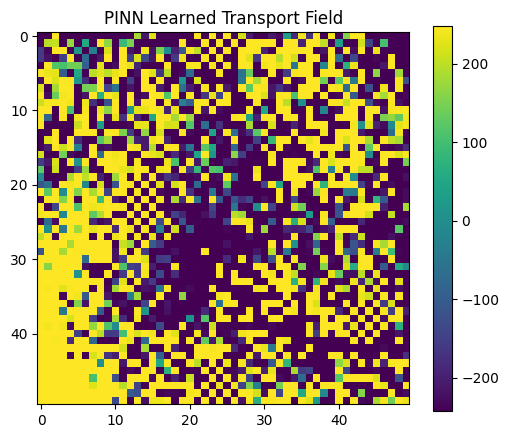


PINN RMSE
640039290424505.8

PINN CAUSAL REGRESSION
[2.26361070e+13 1.38449885e+12]

TRUE VALUES
1.0 2.0


In [ ]:
 

import torch
import torch.nn as nn
import torch.optim as optim

 

nx = 50
ny = 50

# coordinates
x_coords = np.arange(nx)
y_coords = np.arange(ny)

X_grid, Y_grid = np.meshgrid(x_coords, y_coords)

# flatten
x_flat = X_grid.flatten()
y_flat = Y_grid.flatten()

# features
features = np.column_stack([

    x_flat,

    y_flat,

    A_local.flatten(),

    wind_x.flatten(),

    wind_y.flatten(),

    temperature.flatten(),

    humidity.flatten()
])

target = A_spill_true.flatten()

 

X_tensor = torch.tensor(
    features,
    dtype=torch.float32
)

y_tensor = torch.tensor(
    target.reshape(-1,1),
    dtype=torch.float32
)

 

class PINN(nn.Module):

    def __init__(self):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(7,64),

            nn.Tanh(),

            nn.Linear(64,64),

            nn.Tanh(),

            nn.Linear(64,1)
        )

    def forward(self,x):

        return self.network(x)

model = PINN()

 

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

 

n_epochs = 3000

for epoch in range(n_epochs):

    optimizer.zero_grad()

 
    pred = model(X_tensor)

 

    data_loss = torch.mean(
        (pred - y_tensor)**2
    )

  

    pred_2d = pred.reshape(nx, ny)

    # finite differences

    laplacian = (

        torch.roll(pred_2d,1,0)
        + torch.roll(pred_2d,-1,0)
        + torch.roll(pred_2d,1,1)
        + torch.roll(pred_2d,-1,1)
        - 4*pred_2d
    )

    grad_x = torch.roll(pred_2d,-1,0) - pred_2d

    grad_y = torch.roll(pred_2d,-1,1) - pred_2d

    # transport residual

    D = 0.1

    vx_tensor = torch.tensor(
        wind_x,
        dtype=torch.float32
    )

    vy_tensor = torch.tensor(
        wind_y,
        dtype=torch.float32
    )

    pde_residual = (

        D * laplacian

        - vx_tensor * grad_x

        - vy_tensor * grad_y
    )

    pde_loss = torch.mean(
        pde_residual**2
    )

 

    lambda_pde = 0.1

    total_loss = (

        data_loss

        + lambda_pde * pde_loss
    )

    total_loss.backward()

    optimizer.step()

 

    if epoch % 500 == 0:

        print(

            epoch,

            "data_loss =",

            data_loss.item(),

            "pde_loss =",

            pde_loss.item()
        )

 

with torch.no_grad():

    learned_field = model(X_tensor)

learned_field = learned_field.numpy()

learned_field = learned_field.reshape(nx, ny)

 

plt.figure(figsize=(6,5))

plt.imshow(learned_field)

plt.colorbar()

plt.title("PINN Learned Transport Field")

plt.show()

 

rmse = np.sqrt(

    mean_squared_error(

        A_spill_true.flatten(),

        learned_field.flatten()
    )
)

print("\nPINN RMSE")

print(rmse)

 

X_pinn = np.column_stack([

    A_local.flatten(),

    learned_field.flatten()
])

model_causal = LinearRegression()

model_causal.fit(

    X_pinn,

    Y.flatten()
)

print("\nPINN CAUSAL REGRESSION")

print(model_causal.coef_)

print("\nTRUE VALUES")

print(beta1_true, beta2_true)

D = 0.01 vx = 0 sigma = 1
D = 0.01 vx = 0 sigma = 2
D = 0.01 vx = 0 sigma = 3
D = 0.01 vx = 0 sigma = 5
D = 0.01 vx = 0 sigma = 8
D = 0.01 vx = 0 sigma = 10
D = 0.01 vx = 0.5 sigma = 1
D = 0.01 vx = 0.5 sigma = 2
D = 0.01 vx = 0.5 sigma = 3
D = 0.01 vx = 0.5 sigma = 5
D = 0.01 vx = 0.5 sigma = 8
D = 0.01 vx = 0.5 sigma = 10
D = 0.01 vx = 1 sigma = 1
D = 0.01 vx = 1 sigma = 2
D = 0.01 vx = 1 sigma = 3
D = 0.01 vx = 1 sigma = 5
D = 0.01 vx = 1 sigma = 8
D = 0.01 vx = 1 sigma = 10
D = 0.01 vx = 2 sigma = 1
D = 0.01 vx = 2 sigma = 2
D = 0.01 vx = 2 sigma = 3
D = 0.01 vx = 2 sigma = 5
D = 0.01 vx = 2 sigma = 8
D = 0.01 vx = 2 sigma = 10
D = 0.01 vx = 4 sigma = 1
D = 0.01 vx = 4 sigma = 2
D = 0.01 vx = 4 sigma = 3
D = 0.01 vx = 4 sigma = 5
D = 0.01 vx = 4 sigma = 8
D = 0.01 vx = 4 sigma = 10
D = 0.05 vx = 0 sigma = 1
D = 0.05 vx = 0 sigma = 2
D = 0.05 vx = 0 sigma = 3
D = 0.05 vx = 0 sigma = 5
D = 0.05 vx = 0 sigma = 8
D = 0.05 vx = 0 sigma = 10
D = 0.05 vx = 0.5 sigma = 1
D = 0.05 vx = 0.5 

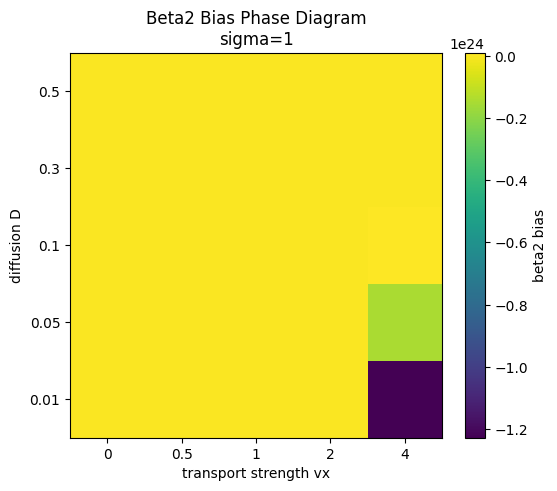

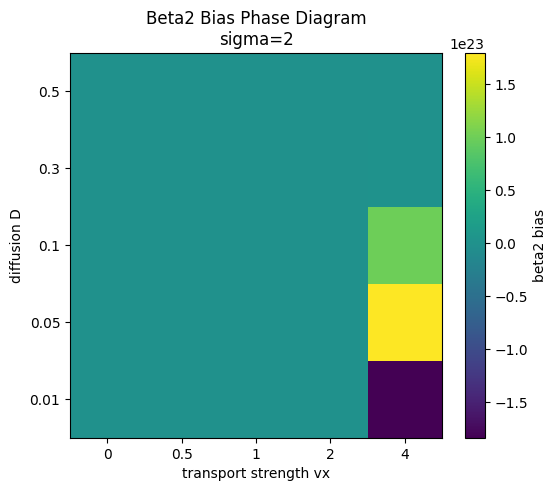

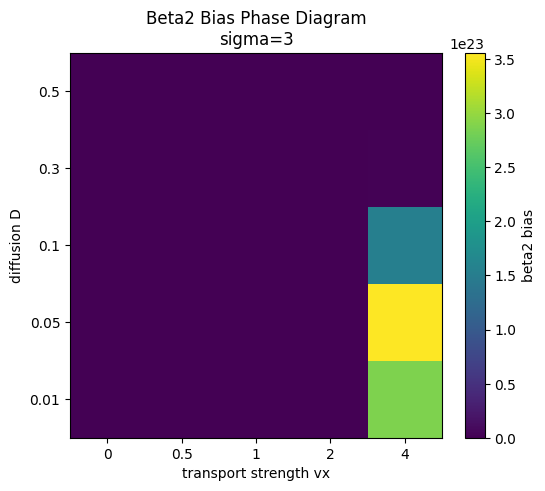

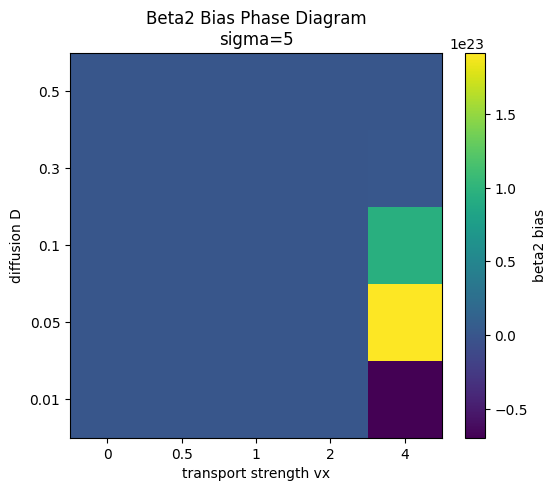

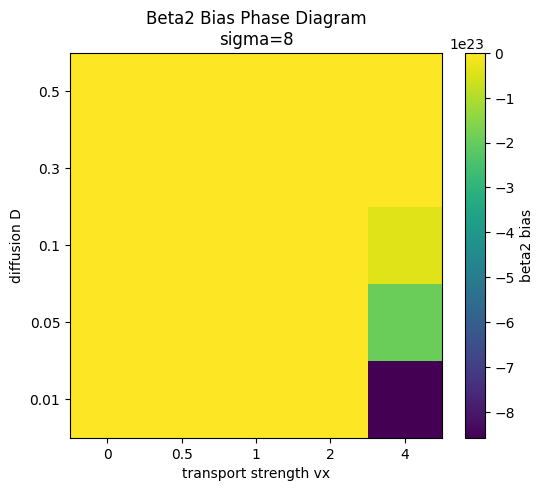

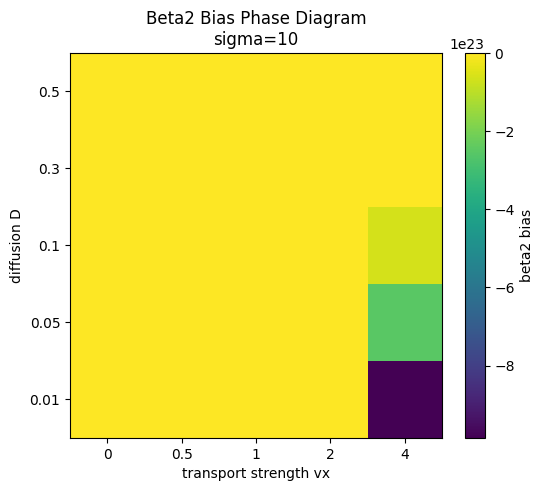

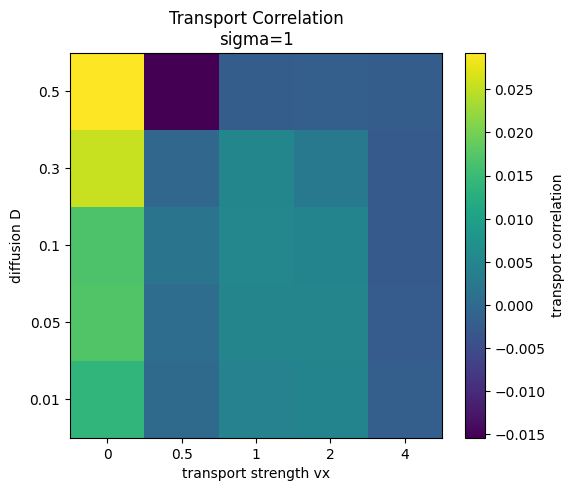

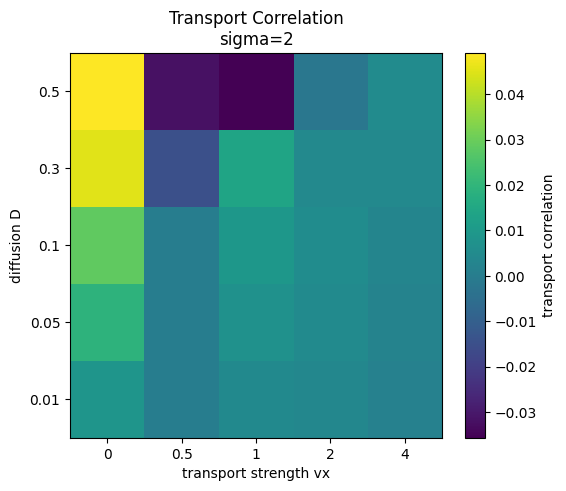

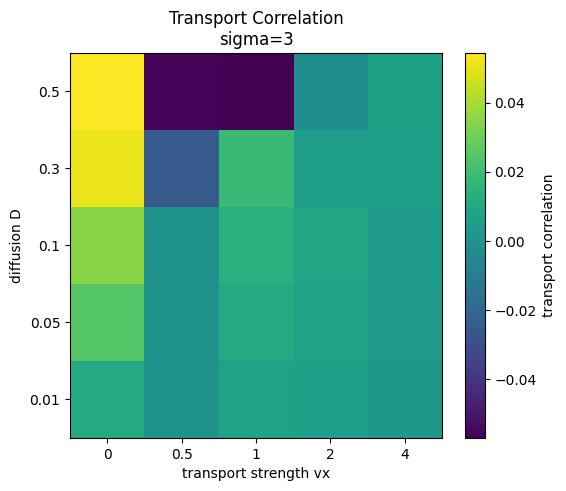

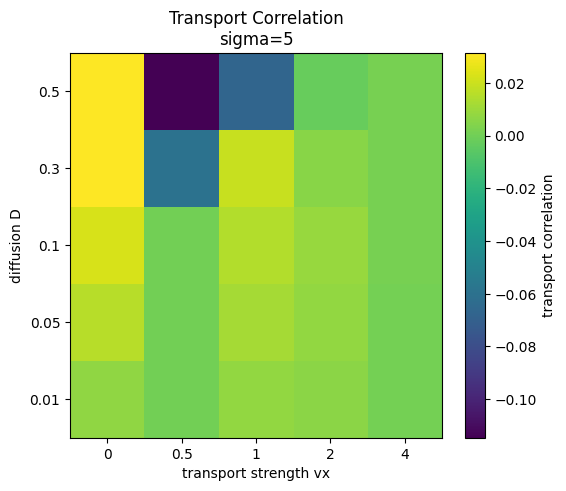

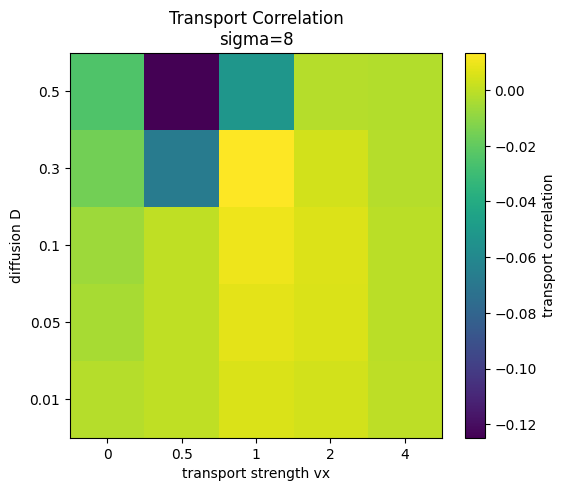

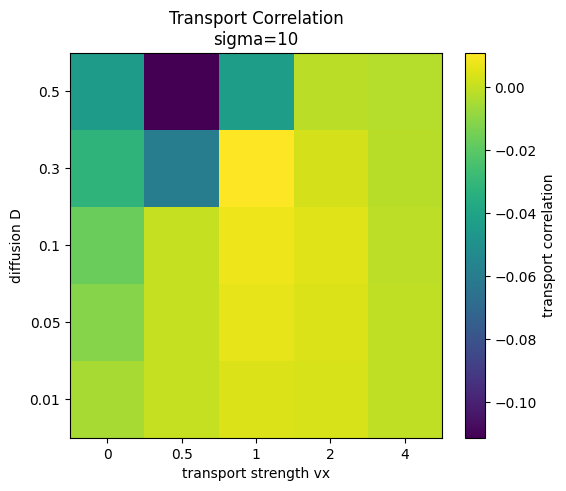

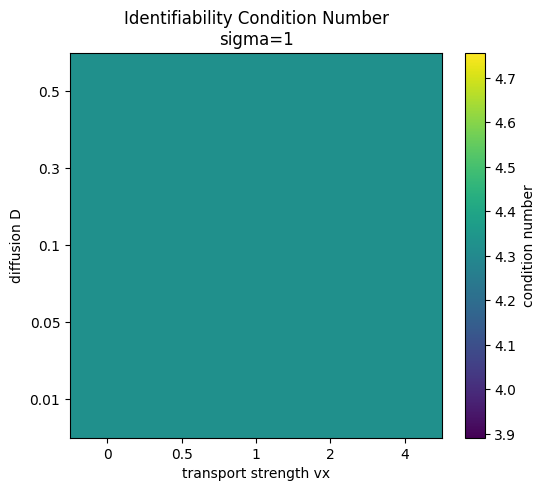

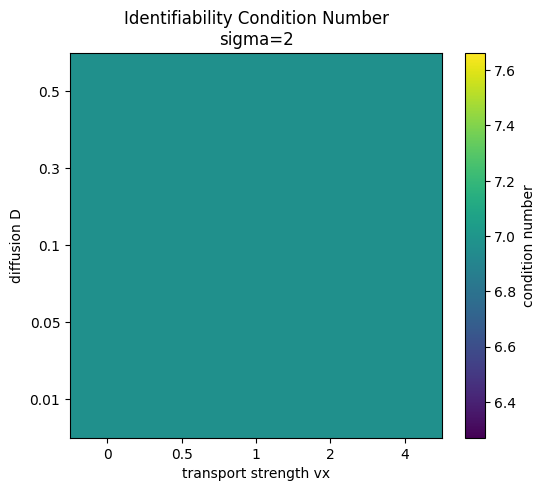

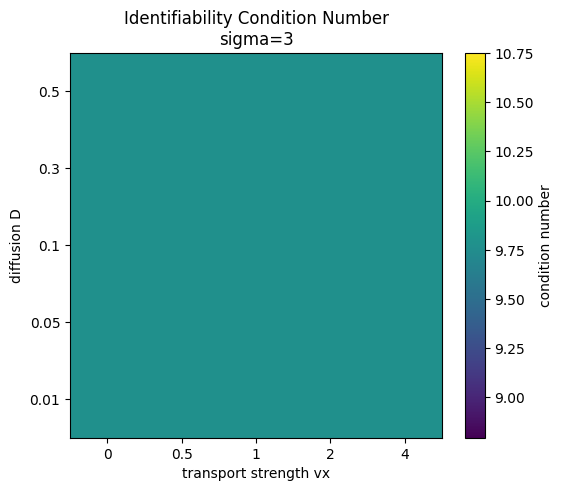

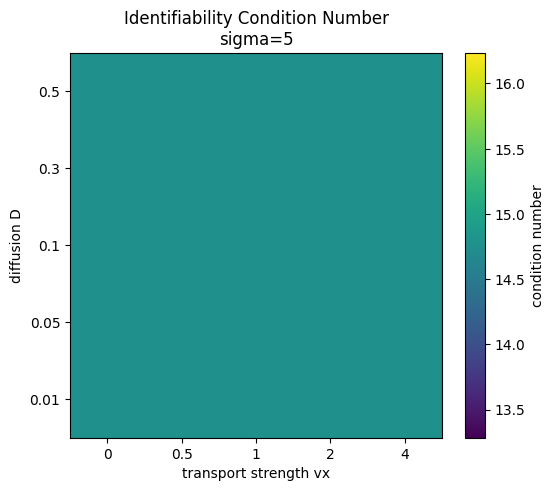

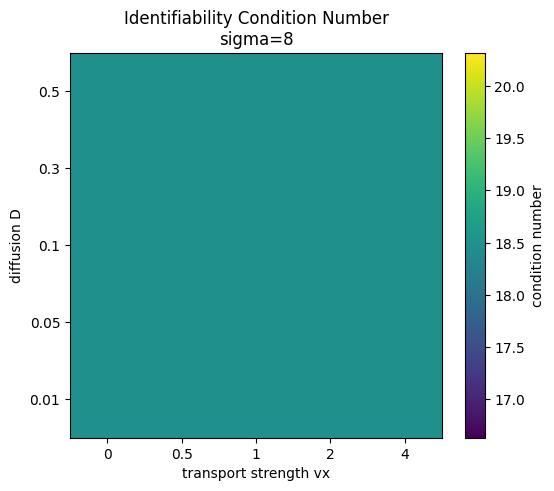

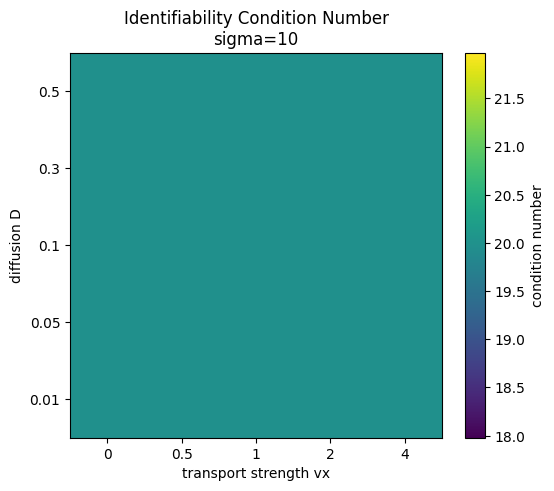


FAILURE REGION
        D   vx  sigma  corr_local_gaussian  condition_number  transport_corr  \
0    0.01  0.0      1             0.574377          4.323927        0.014063   
1    0.01  0.0      2             0.287875          6.966580        0.008549   
2    0.01  0.0      3             0.193700          9.772967        0.011133   
3    0.01  0.0      5             0.118326         14.759754        0.007304   
4    0.01  0.0      8             0.068882         18.474791       -0.001861   
..    ...  ...    ...                  ...               ...             ...   
145  0.50  4.0      2             0.287875          6.966580        0.005306   
146  0.50  4.0      3             0.193700          9.772967        0.006759   
147  0.50  4.0      5             0.118326         14.759754        0.001583   
148  0.50  4.0      8             0.068882         18.474791       -0.002592   
149  0.50  4.0     10             0.058695         19.975739       -0.002826   

        beta2_hat    be

In [ ]:
 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter
from sklearn.linear_model import LinearRegression
from numpy.linalg import cond

 

nx = 50
ny = 50

beta1_true = 1.0
beta2_true = 2.0

 

A_local = np.random.normal(
    size=(nx, ny)
)

 

u0 = np.zeros((nx, ny))

u0[10,10] = 100
u0[35,20] = 80
u0[25,40] = 60
 

def simulate_transport(
    u_init,
    D,
    vx,
    vy,
    dt=0.1,
    n_steps=100
):

    u = u_init.copy()

    for t in range(n_steps):

        laplacian = (

            np.roll(u,1,axis=0)
            + np.roll(u,-1,axis=0)
            + np.roll(u,1,axis=1)
            + np.roll(u,-1,axis=1)
            - 4*u
        )

        grad_x = np.roll(u,-1,axis=0) - u

        grad_y = np.roll(u,-1,axis=1) - u

        u = u + dt * (

            D * laplacian

            - vx * grad_x

            - vy * grad_y
        )

    return u

 

# diffusion strength
Ds = [0.01, 0.05, 0.1, 0.3, 0.5]

# transport strength
vxs = [0, 0.5, 1, 2, 4]

# Gaussian smoothing
sigmas = [1,2,3,5,8,10]

 

results = []

 
for D in Ds:

    for vx in vxs:

        for sigma in sigmas:

            print(
                "D =", D,
                "vx =", vx,
                "sigma =", sigma
            )

      

            A_spill_true = simulate_transport(

                u_init=u0,

                D=D,

                vx=vx,

                vy=0
            )

 

            epsilon = np.random.normal(
                scale=0.5,
                size=(nx, ny)
            )

            Y = (

                beta1_true * A_local

                + beta2_true * A_spill_true

                + epsilon
            )

            y = Y.flatten()

     

            A_spill_gaussian = gaussian_filter(

                A_local,

                sigma=sigma
            )

 
            X = np.column_stack([

                A_local.flatten(),

                A_spill_gaussian.flatten()
            ])

            model = LinearRegression()

            model.fit(X, y)

            beta1_hat = model.coef_[0]

            beta2_hat = model.coef_[1]

    

            corr = np.corrcoef(

                A_local.flatten(),

                A_spill_gaussian.flatten()

            )[0,1]

            condition_number = cond(X)

 

            beta2_bias = (
                beta2_hat - beta2_true
            )

     

            transport_corr = np.corrcoef(

                A_spill_true.flatten(),

                A_spill_gaussian.flatten()

            )[0,1]

   

            results.append({

                "D": D,

                "vx": vx,

                "sigma": sigma,

                "corr_local_gaussian": corr,

                "condition_number": condition_number,

                "transport_corr": transport_corr,

                "beta2_hat": beta2_hat,

                "beta2_bias": beta2_bias
            })
 
results_df = pd.DataFrame(results)

print(results_df)

 
for sigma in sigmas:

    subset = results_df[
        results_df["sigma"] == sigma
    ]

    pivot = subset.pivot(

        index="D",

        columns="vx",

        values="beta2_bias"
    )

    plt.figure(figsize=(6,5))

    plt.imshow(
        pivot,
        aspect='auto',
        origin='lower'
    )

    plt.colorbar(
        label='beta2 bias'
    )

    plt.xticks(
        range(len(vxs)),
        vxs
    )

    plt.yticks(
        range(len(Ds)),
        Ds
    )

    plt.xlabel("transport strength vx")

    plt.ylabel("diffusion D")

    plt.title(
        f"Beta2 Bias Phase Diagram\nsigma={sigma}"
    )

    plt.show()
 

for sigma in sigmas:

    subset = results_df[
        results_df["sigma"] == sigma
    ]

    pivot = subset.pivot(

        index="D",

        columns="vx",

        values="transport_corr"
    )

    plt.figure(figsize=(6,5))

    plt.imshow(
        pivot,
        aspect='auto',
        origin='lower'
    )

    plt.colorbar(
        label='transport correlation'
    )

    plt.xticks(
        range(len(vxs)),
        vxs
    )

    plt.yticks(
        range(len(Ds)),
        Ds
    )

    plt.xlabel("transport strength vx")

    plt.ylabel("diffusion D")

    plt.title(
        f"Transport Correlation\nsigma={sigma}"
    )

    plt.show()

 
for sigma in sigmas:

    subset = results_df[
        results_df["sigma"] == sigma
    ]

    pivot = subset.pivot(

        index="D",

        columns="vx",

        values="condition_number"
    )

    plt.figure(figsize=(6,5))

    plt.imshow(
        pivot,
        aspect='auto',
        origin='lower'
    )

    plt.colorbar(
        label='condition number'
    )

    plt.xticks(
        range(len(vxs)),
        vxs
    )

    plt.yticks(
        range(len(Ds)),
        Ds
    )

    plt.xlabel("transport strength vx")

    plt.ylabel("diffusion D")

    plt.title(
        f"Identifiability Condition Number\nsigma={sigma}"
    )

    plt.show()

 

failure_region = results_df[

    np.abs(results_df["beta2_bias"]) > 1

]

 

print(failure_region)

 

best_region = results_df[

    np.abs(results_df["beta2_bias"]) < 0.1

]

 
print(best_region)

In [ ]:
 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter

from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error

from sklearn.model_selection import train_test_split

 

nx = 50
ny = 50

beta1_true = 1.0
beta2_true = 2.0

n_replications = 30

 

def simulate_transport(
    u_init,
    D,
    vx,
    vy,
    dt=0.01,
    n_steps=30
):

    u = u_init.copy()

    for t in range(n_steps):

        laplacian = (

            np.roll(u,1,axis=0)
            + np.roll(u,-1,axis=0)
            + np.roll(u,1,axis=1)
            + np.roll(u,-1,axis=1)
            - 4*u
        )

        grad_x = np.roll(u,-1,axis=0) - u

        grad_y = np.roll(u,-1,axis=1) - u

        u = u + dt * (

            D * laplacian

            - vx * grad_x

            - vy * grad_y
        )

    return u

 

results = []

 

for rep in range(n_replications):

 

 

    D = np.random.uniform(0.01,0.5)

    vx = np.random.uniform(0,0.5)

    vy = np.random.uniform(0,0.3)

    sigma = np.random.choice([1,2,3,5,8])

   

    A_local = np.random.normal(
        size=(nx, ny)
    )

 

    u0 = np.zeros((nx, ny))

    u0[10,10] = 100
    u0[35,20] = 80
    u0[25,40] = 60

 

    wind_x = np.ones((nx, ny)) * vx

    wind_y = np.ones((nx, ny)) * vy

    temperature = np.random.normal(
        25,
        3,
        size=(nx, ny)
    )

    humidity = np.random.normal(
        60,
        10,
        size=(nx, ny)
    )

 

    A_spill_true = simulate_transport(

        u0,

        D,

        vx,

        vy
    )

 

    epsilon = np.random.normal(
        scale=0.5,
        size=(nx, ny)
    )

    Y = (

        beta1_true * A_local

        + beta2_true * A_spill_true

        + epsilon
    )
 

    X_features = np.column_stack([

        A_local.flatten(),

        wind_x.flatten(),

        wind_y.flatten(),

        temperature.flatten(),

        humidity.flatten()
    ])

    y_spill = A_spill_true.flatten()


REPLICATION 0

REPLICATION 1

REPLICATION 2

REPLICATION 3

REPLICATION 4

REPLICATION 5

REPLICATION 6

REPLICATION 7

REPLICATION 8

REPLICATION 9

REPLICATION 10

REPLICATION 11

REPLICATION 12

REPLICATION 13

REPLICATION 14

REPLICATION 15

REPLICATION 16

REPLICATION 17

REPLICATION 18

REPLICATION 19

REPLICATION 20

REPLICATION 21

REPLICATION 22

REPLICATION 23

REPLICATION 24

REPLICATION 25

REPLICATION 26

REPLICATION 27

REPLICATION 28

REPLICATION 29


In [ ]:
 

        X_train, X_test, y_train, y_test = train_test_split(

                X_features,

                   y_spill,

                  test_size=0.3,
  
             random_state=123
             )

 

    A_spill_gaussian = gaussian_filter(

        A_local,

        sigma=sigma
    )

    gaussian_rmse = np.sqrt(

        mean_squared_error(

            A_spill_true.flatten(),

            A_spill_gaussian.flatten()
        )
    )
 
    X_causal_gaussian = np.column_stack([

        A_local.flatten(),

        A_spill_gaussian.flatten()
    ])

    causal_gaussian = LinearRegression()

    causal_gaussian.fit(

        X_causal_gaussian,

        Y.flatten()
    )

    beta1_gaussian = causal_gaussian.coef_[0]

    beta2_gaussian = causal_gaussian.coef_[1]
 

    nn_model = MLPRegressor(

        hidden_layer_sizes=(64,64),

        activation='relu',

        max_iter=1000,

        random_state=123
    )

    nn_model.fit(

        X_train,

        y_train
    )
 

    y_pred_test = nn_model.predict(X_test)

    nn_rmse = np.sqrt(

        mean_squared_error(

            y_test,

            y_pred_test
        )
    )

 

    A_spill_nn = nn_model.predict(
        X_features
    )

 

    X_causal_nn = np.column_stack([

        A_local.flatten(),

        A_spill_nn
    ])

    causal_nn = LinearRegression()

    causal_nn.fit(

        X_causal_nn,

        Y.flatten()
    )

    beta1_nn = causal_nn.coef_[0]

    beta2_nn = causal_nn.coef_[1]

 

    x_coords = np.arange(nx)

    y_coords = np.arange(ny)

    X_grid, Y_grid = np.meshgrid(

        x_coords,

        y_coords
    )

 

    pinn_features = np.column_stack([

        X_grid.flatten(),

        Y_grid.flatten(),

        A_local.flatten(),

        wind_x.flatten(),

        wind_y.flatten(),

        temperature.flatten(),

        humidity.flatten()
    ])

 

    pinn_model = MLPRegressor(

        hidden_layer_sizes=(128,128),

        activation='tanh',

        max_iter=1000,

        random_state=123
    )

    pinn_model.fit(

        pinn_features,

        y_spill
    )

 

    A_spill_pinn = pinn_model.predict(

        pinn_features
    )

 

    A_spill_pinn = A_spill_pinn.reshape(nx, ny)

    A_spill_pinn = gaussian_filter(

        A_spill_pinn,

        sigma=1
    )

    pinn_rmse = np.sqrt(

        mean_squared_error(

            A_spill_true.flatten(),

            A_spill_pinn.flatten()
        )
    )

 

    X_causal_pinn = np.column_stack([

        A_local.flatten(),

        A_spill_pinn.flatten()
    ])

    causal_pinn = LinearRegression()

    causal_pinn.fit(

        X_causal_pinn,

        Y.flatten()
    )

    beta1_pinn = causal_pinn.coef_[0]

    beta2_pinn = causal_pinn.coef_[1]

 

    results.append({

 

        "replication": rep,

        "D": D,

        "vx": vx,

        "vy": vy,

        "sigma": sigma,

 

        "gaussian_rmse": gaussian_rmse,

        "beta1_gaussian": beta1_gaussian,

        "beta2_gaussian": beta2_gaussian,

        "beta2_bias_gaussian":

            beta2_gaussian - beta2_true,

 

        "nn_rmse": nn_rmse,

        "beta1_nn": beta1_nn,

        "beta2_nn": beta2_nn,

        "beta2_bias_nn":

            beta2_nn - beta2_true,

 

        "pinn_rmse": pinn_rmse,

        "beta1_pinn": beta1_pinn,

        "beta2_pinn": beta2_pinn,

        "beta2_bias_pinn":

            beta2_pinn - beta2_true
    })

 

results_df = pd.DataFrame(results)

print("\n========================")
print("FINAL RESULTS")
print("========================")

print(results_df)

 

summary = pd.DataFrame({

    "method":[

        "gaussian",

        "nn",

        "pinn"
    ],

 

    "mean_rmse":[

        results_df["gaussian_rmse"].mean(),

        results_df["nn_rmse"].mean(),

        results_df["pinn_rmse"].mean()
    ],

 

    "mean_beta2_bias":[

        results_df["beta2_bias_gaussian"].mean(),

        results_df["beta2_bias_nn"].mean(),

        results_df["beta2_bias_pinn"].mean()
    ],

 

    "mean_abs_beta2_bias":[

        np.mean(

            np.abs(

                results_df["beta2_bias_gaussian"]
            )
        ),

        np.mean(

            np.abs(

                results_df["beta2_bias_nn"]
            )
        ),

        np.mean(

            np.abs(

                results_df["beta2_bias_pinn"]
            )
        )
    ]
})

 
print(summary)

 

methods = [

    "gaussian",

    "nn",

    "pinn"
]

rmse_values = [

    results_df["gaussian_rmse"],

    results_df["nn_rmse"],

    results_df["pinn_rmse"]
]

plt.figure(figsize=(7,5))

plt.boxplot(rmse_values)

plt.xticks(

    [1,2,3],

    methods
)

plt.ylabel("RMSE")

plt.title("Transport Recovery Error")

plt.show()

 

bias_values = [

    results_df["beta2_bias_gaussian"],

    results_df["beta2_bias_nn"],

    results_df["beta2_bias_pinn"]
]

plt.figure(figsize=(7,5))

plt.boxplot(bias_values)

plt.xticks(

    [1,2,3],

    methods
)

plt.axhline(

    0,

    linestyle='--'
)

plt.ylabel("beta2 bias")

plt.title("Spillover Effect Bias")

plt.show()

 

plt.figure(figsize=(7,5))

plt.scatter(

    results_df["vx"],

    np.abs(
        results_df["beta2_bias_gaussian"]
    ),

    alpha=0.7
)

plt.xlabel("transport strength vx")

plt.ylabel("|beta2 bias|")

plt.title(

    "Gaussian Bias vs Transport Strength"
)

plt.show()

 

failure_region = results_df[

    np.abs(

        results_df["beta2_bias_gaussian"]

    ) > 1
]
 

print(

    failure_region[[
        "D",
        "vx",
        "vy",
        "sigma",
        "beta2_bias_gaussian"
    ]]
)

IndentationError: unindent does not match any outer indentation level (<tokenize>, line 39)

(30, 50, 50)


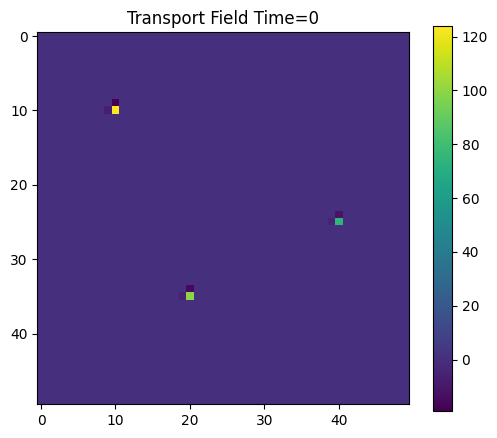

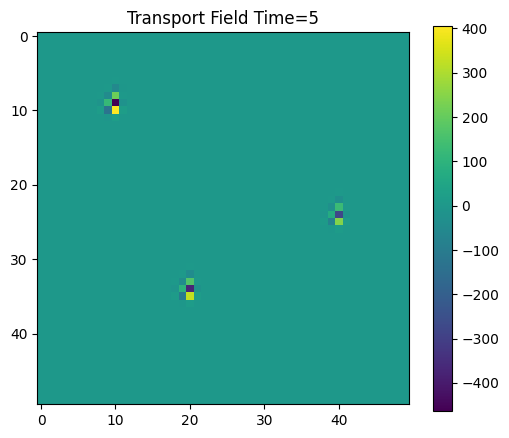

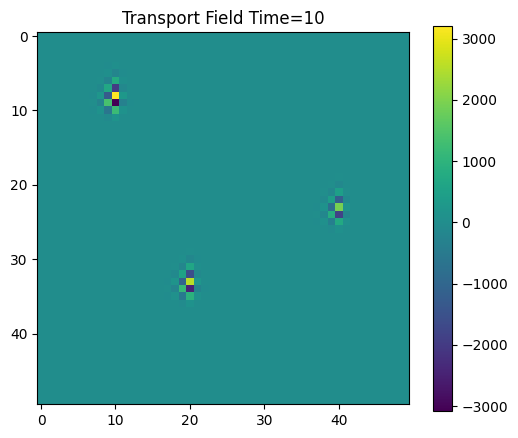

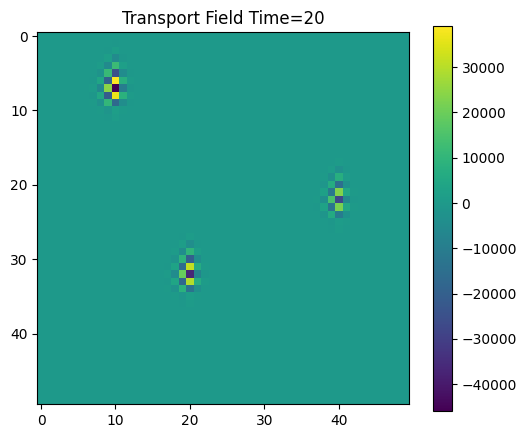

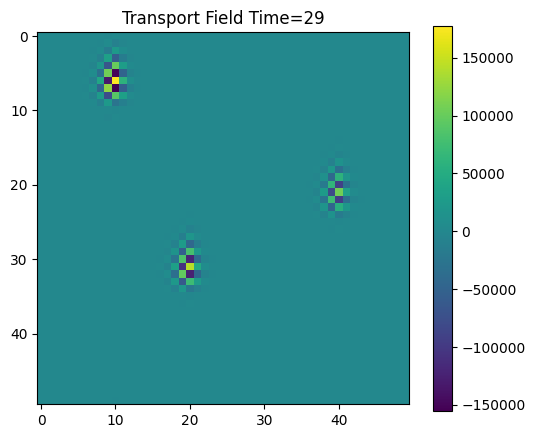

   time  x  y  local_exposure  spillover_true   outcome
0     0  0  0       -2.167165             0.0 -2.518446
1     0  0  1        0.244694             0.0  0.648742
2     0  0  2        1.586796             0.0  1.264355
3     0  0  3       -1.278867             0.0 -1.330857
4     0  0  4       -0.952009             0.0 -1.127056

GAUSSIAN MODEL
[-2.23284685  5.79763414]

TRUE MODEL
[0.99986224 1.99999999]

GAUSSIAN RMSE
3706.349366845632


In [ ]:
 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter

 
nx = 50
ny = 50

T = 30

 
u = np.zeros((nx, ny))

u[10,10] = 100
u[35,20] = 80
u[25,40] = 60

 

transport_history = []

 

for t in range(T):

 

    vx = 2 + np.sin(t / 5)

    vy = 0.5 + 0.3 * np.cos(t / 6)

    D = 0.1 + 0.05 * np.sin(t / 10)

 

    laplacian = (

        np.roll(u,1,axis=0)

        + np.roll(u,-1,axis=0)

        + np.roll(u,1,axis=1)

        + np.roll(u,-1,axis=1)

        - 4*u
    )

    grad_x = np.roll(u,-1,axis=0) - u

    grad_y = np.roll(u,-1,axis=1) - u

 

    u = u + 0.1 * (

        D * laplacian

        - vx * grad_x

        - vy * grad_y
    )

 

    transport_history.append(
        u.copy()
    )

 

transport_history = np.array(
    transport_history
)

print(
    transport_history.shape
)

 

 

time_points = [0,5,10,20,29]

for t in time_points:

    plt.figure(figsize=(6,5))

    plt.imshow(
        transport_history[t]
    )

    plt.colorbar()

    plt.title(
        f"Transport Field Time={t}"
    )

    plt.show()

 

A_local_time = np.random.normal(

    size=(T, nx, ny)
)

 

A_spill_true_time = transport_history.copy()

 

beta1_true = 1.0
beta2_true = 2.0

Y_time = []

for t in range(T):

    epsilon = np.random.normal(
        scale=0.5,
        size=(nx, ny)
    )

    Y_t = (

        beta1_true * A_local_time[t]

        + beta2_true * A_spill_true_time[t]

        + epsilon
    )

    Y_time.append(Y_t)

Y_time = np.array(Y_time)

 

rows = []

for t in range(T):

    for i in range(nx):

        for j in range(ny):

            rows.append({

                "time": t,

                "x": i,

                "y": j,

                "local_exposure":

                    A_local_time[t,i,j],

                "spillover_true":

                    A_spill_true_time[t,i,j],

                "outcome":

                    Y_time[t,i,j]
            })

panel_df = pd.DataFrame(rows)

print(panel_df.head())

 

gaussian_spillover_time = []

for t in range(T):

    gaussian_t = gaussian_filter(

        A_local_time[t],

        sigma=5
    )

    gaussian_spillover_time.append(
        gaussian_t
    )

gaussian_spillover_time = np.array(
    gaussian_spillover_time
)

 

X_gaussian = np.column_stack([

    A_local_time.flatten(),

    gaussian_spillover_time.flatten()
])

y = Y_time.flatten()

 

from sklearn.linear_model import LinearRegression

model_gaussian = LinearRegression()

model_gaussian.fit(
    X_gaussian,
    y
)

print("\nGAUSSIAN MODEL")

print(model_gaussian.coef_)

 

X_true = np.column_stack([

    A_local_time.flatten(),

    A_spill_true_time.flatten()
])

model_true = LinearRegression()

model_true.fit(
    X_true,
    y
)

print("\nTRUE MODEL")

print(model_true.coef_)

 

rmse_gaussian = np.sqrt(

    np.mean(

        (
            gaussian_spillover_time

            - A_spill_true_time

        )**2
    )
)

print("\nGAUSSIAN RMSE")

print(rmse_gaussian)

 

(35, 5, 3600)
(35, 900)
0 85503860736.0
50 85503729664.0
100 85503565824.0
150 85503426560.0
200 85503279104.0
250 85503131648.0
300 85502984192.0
350 85502836736.0
400 85502697472.0
450 85502550016.0

LSTM RMSE
292407.9064242793


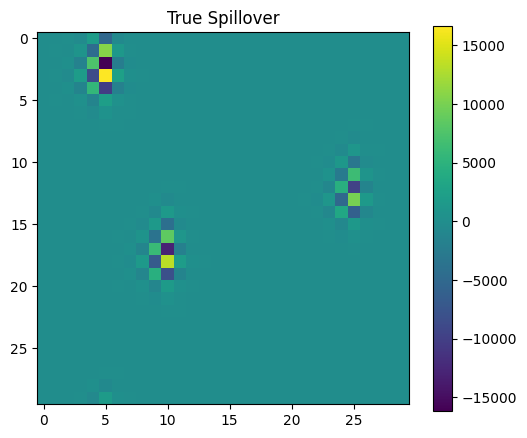

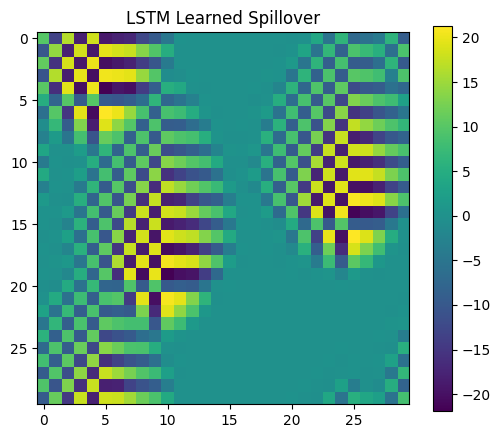


CAUSAL ESTIMATES
[4885.91048331 8610.04520385]

TRUE VALUES
1.0 2.0


In [ ]:
 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression

import torch
import torch.nn as nn
import torch.optim as optim

 
nx = 30
ny = 30

T = 40

beta1_true = 1.0
beta2_true = 2.0

 

u = np.zeros((nx, ny))

u[5,5] = 100
u[20,10] = 80
u[15,25] = 60

 

transport_history = []

weather_history = []

 

for t in range(T):

 

    vx = 2 + np.sin(t / 5)

    vy = 0.5 + 0.3 * np.cos(t / 6)

    D = 0.1 + 0.05 * np.sin(t / 10)

 

    laplacian = (

        np.roll(u,1,axis=0)

        + np.roll(u,-1,axis=0)

        + np.roll(u,1,axis=1)

        + np.roll(u,-1,axis=1)

        - 4*u
    )

    grad_x = np.roll(u,-1,axis=0) - u

    grad_y = np.roll(u,-1,axis=1) - u

    u = u + 0.1 * (

        D * laplacian

        - vx * grad_x

        - vy * grad_y
    )

 

    transport_history.append(
        u.copy()
    )

    weather_history.append([

        vx,

        vy,

        D
    ])

transport_history = np.array(
    transport_history
)

weather_history = np.array(
    weather_history
)

 

A_local_time = np.random.normal(

    size=(T, nx, ny)
)

 

Y_time = []

for t in range(T):

    epsilon = np.random.normal(
        scale=0.5,
        size=(nx, ny)
    )

    Y_t = (

        beta1_true * A_local_time[t]

        + beta2_true * transport_history[t]

        + epsilon
    )

    Y_time.append(Y_t)

Y_time = np.array(Y_time)

 

sequence_length = 5

X_sequences = []

y_sequences = []

 

for t in range(sequence_length, T):

 

    pollution_sequence = []

    for k in range(t-sequence_length, t):

        pollution_sequence.append(

            transport_history[k].flatten()
        )

    pollution_sequence = np.array(
        pollution_sequence
    )

 

    weather_sequence = weather_history[
        t-sequence_length:t
    ]

 

    combined_sequence = np.concatenate([

        pollution_sequence,

        np.repeat(

            weather_sequence,

            nx*ny,

            axis=1
        )
    ], axis=1)

    X_sequences.append(
        combined_sequence
    )

 
    y_sequences.append(

        transport_history[t].flatten()
    )

X_sequences = np.array(
    X_sequences
)

y_sequences = np.array(
    y_sequences
)

print(X_sequences.shape)
print(y_sequences.shape)

 

X_tensor = torch.tensor(

    X_sequences,

    dtype=torch.float32
)

y_tensor = torch.tensor(

    y_sequences,

    dtype=torch.float32
)

 

class TransportLSTM(nn.Module):

    def __init__(self):

        super().__init__()

        input_size = X_sequences.shape[2]

        hidden_size = 128

        self.lstm = nn.LSTM(

            input_size=input_size,

            hidden_size=hidden_size,

            batch_first=True
        )

        self.fc = nn.Linear(

            hidden_size,

            nx * ny
        )

    def forward(self,x):

        lstm_out, _ = self.lstm(x)

        last_hidden = lstm_out[:,-1,:]

        out = self.fc(last_hidden)

        return out

model = TransportLSTM()

 

optimizer = optim.Adam(

    model.parameters(),

    lr=0.001
)

criterion = nn.MSELoss()

 

n_epochs = 500

for epoch in range(n_epochs):

    optimizer.zero_grad()

    pred = model(X_tensor)

    loss = criterion(

        pred,

        y_tensor
    )

    loss.backward()

    optimizer.step()

    if epoch % 50 == 0:

        print(

            epoch,

            loss.item()
        )

 

with torch.no_grad():

    learned_spillover = model(
        X_tensor
    )

learned_spillover = learned_spillover.numpy()

 

rmse = np.sqrt(

    mean_squared_error(

        y_sequences.flatten(),

        learned_spillover.flatten()
    )
)

print("\nLSTM RMSE")

print(rmse)

 

example_t = 10

true_field = y_sequences[
    example_t
].reshape(nx, ny)

pred_field = learned_spillover[
    example_t
].reshape(nx, ny)

plt.figure(figsize=(6,5))

plt.imshow(true_field)

plt.colorbar()

plt.title("True Spillover")

plt.show()

plt.figure(figsize=(6,5))

plt.imshow(pred_field)

plt.colorbar()

plt.title("LSTM Learned Spillover")

plt.show()

 

A_local_flat = A_local_time[
    sequence_length:T
].reshape(-1)

A_spill_flat = learned_spillover.reshape(-1)

Y_flat = Y_time[
    sequence_length:T
].reshape(-1)

X_causal = np.column_stack([

    A_local_flat,

    A_spill_flat
])

causal_model = LinearRegression()

causal_model.fit(

    X_causal,

    Y_flat
)

print("\nCAUSAL ESTIMATES")

print(causal_model.coef_)

print("\nTRUE VALUES")

print(beta1_true, beta2_true)

 

0 data_loss = 85503868928.0 pde_loss = 0.6580622792243958
50 data_loss = 85503729664.0 pde_loss = 24.235475540161133
100 data_loss = 85503590400.0 pde_loss = 102.09223175048828
150 data_loss = 85503442944.0 pde_loss = 235.1527862548828
200 data_loss = 85503287296.0 pde_loss = 409.2431335449219
250 data_loss = 85503131648.0 pde_loss = 658.64013671875
300 data_loss = 85503008768.0 pde_loss = 933.7568359375
350 data_loss = 85502861312.0 pde_loss = 1250.590576171875
400 data_loss = 85502705664.0 pde_loss = 1638.0628662109375
450 data_loss = 85502558208.0 pde_loss = 2090.551513671875

PINN-LSTM RMSE
292408.01834210445


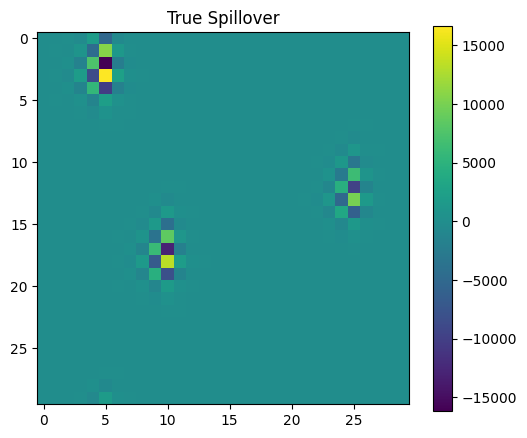

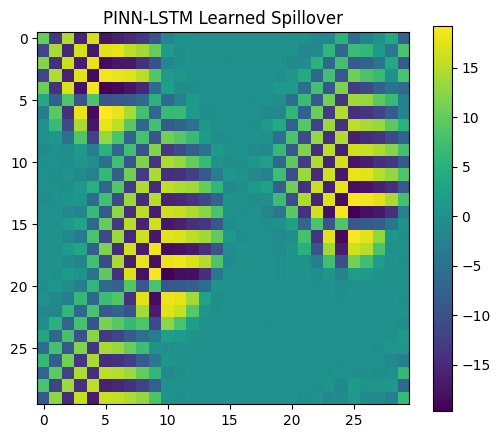


CAUSAL ESTIMATES
[1087.18491258 9934.57753337]

TRUE VALUES
1.0 2.0


In [ ]:
 
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression

 

nx = 30
ny = 30

T = 40

sequence_length = 5

beta1_true = 1.0
beta2_true = 2.0

 

u = np.zeros((nx, ny))

u[5,5] = 100
u[20,10] = 80
u[15,25] = 60

 

transport_history = []

weather_history = []

 

for t in range(T):

    vx = 2 + np.sin(t/5)

    vy = 0.5 + 0.3*np.cos(t/6)

    D = 0.1 + 0.05*np.sin(t/10)

    laplacian = (

        np.roll(u,1,axis=0)

        + np.roll(u,-1,axis=0)

        + np.roll(u,1,axis=1)

        + np.roll(u,-1,axis=1)

        - 4*u
    )

    grad_x = np.roll(u,-1,axis=0) - u

    grad_y = np.roll(u,-1,axis=1) - u

    u = u + 0.1 * (

        D * laplacian

        - vx * grad_x

        - vy * grad_y
    )

    transport_history.append(
        u.copy()
    )

    weather_history.append([

        vx,

        vy,

        D
    ])

transport_history = np.array(
    transport_history
)

weather_history = np.array(
    weather_history
)

 

A_local_time = np.random.normal(

    size=(T, nx, ny)
)

 

Y_time = []

for t in range(T):

    epsilon = np.random.normal(
        scale=0.5,
        size=(nx, ny)
    )

    Y_t = (

        beta1_true * A_local_time[t]

        + beta2_true * transport_history[t]

        + epsilon
    )

    Y_time.append(Y_t)

Y_time = np.array(Y_time)

 

X_sequences = []

y_sequences = []

weather_sequences = []

for t in range(sequence_length, T):

    pollution_sequence = []

    for k in range(t-sequence_length, t):

        pollution_sequence.append(

            transport_history[k].flatten()
        )

    pollution_sequence = np.array(
        pollution_sequence
    )

    weather_seq = weather_history[
        t-sequence_length:t
    ]

    combined_sequence = np.concatenate([

        pollution_sequence,

        np.repeat(

            weather_seq,

            nx*ny,

            axis=1
        )

    ], axis=1)

    X_sequences.append(
        combined_sequence
    )

    y_sequences.append(

        transport_history[t].flatten()
    )

    weather_sequences.append(

        weather_history[t]
    )

X_sequences = np.array(
    X_sequences
)

y_sequences = np.array(
    y_sequences
)

weather_sequences = np.array(
    weather_sequences
)

 

X_tensor = torch.tensor(

    X_sequences,

    dtype=torch.float32
)

y_tensor = torch.tensor(

    y_sequences,

    dtype=torch.float32
)

weather_tensor = torch.tensor(

    weather_sequences,

    dtype=torch.float32
)

 

class PINNLSTM(nn.Module):

    def __init__(self):

        super().__init__()

        input_size = X_sequences.shape[2]

        hidden_size = 128

        self.lstm = nn.LSTM(

            input_size=input_size,

            hidden_size=hidden_size,

            batch_first=True
        )

        self.fc = nn.Linear(

            hidden_size,

            nx * ny
        )

    def forward(self,x):

        lstm_out, _ = self.lstm(x)

        hidden = lstm_out[:,-1,:]

        out = self.fc(hidden)

        return out

model = PINNLSTM()

 

optimizer = optim.Adam(

    model.parameters(),

    lr=0.001
)

 

n_epochs = 500

lambda_pde = 0.1

for epoch in range(n_epochs):

    optimizer.zero_grad()

 

    pred = model(X_tensor)

    

    data_loss = torch.mean(

        (pred - y_tensor)**2
    )

 

    pred_2d = pred.reshape(

        -1,

        nx,

        ny
    )

    pde_losses = []

    for b in range(pred_2d.shape[0]):

        field = pred_2d[b]

        vx = weather_tensor[b,0]

        vy = weather_tensor[b,1]

        D = weather_tensor[b,2]

   

        laplacian = (

            torch.roll(field,1,0)

            + torch.roll(field,-1,0)

            + torch.roll(field,1,1)

            + torch.roll(field,-1,1)

            - 4*field
        )

        grad_x = (

            torch.roll(field,-1,0)

            - field
        )

        grad_y = (

            torch.roll(field,-1,1)

            - field
        )

     

        residual = (

            D * laplacian

            - vx * grad_x

            - vy * grad_y
        )

        pde_losses.append(

            torch.mean(
                residual**2
            )
        )

    pde_loss = torch.mean(

        torch.stack(pde_losses)
    )

    

    total_loss = (

        data_loss

        + lambda_pde * pde_loss
    )

    total_loss.backward()

    optimizer.step()

  

    if epoch % 50 == 0:

        print(

            epoch,

            "data_loss =",

            data_loss.item(),

            "pde_loss =",

            pde_loss.item()
        )

 

with torch.no_grad():

    learned_spillover = model(
        X_tensor
    )

learned_spillover = learned_spillover.numpy()

 

rmse = np.sqrt(

    mean_squared_error(

        y_sequences.flatten(),

        learned_spillover.flatten()
    )
)

print("\nPINN-LSTM RMSE")

print(rmse)

 

example_t = 10

true_field = y_sequences[
    example_t
].reshape(nx, ny)

pred_field = learned_spillover[
    example_t
].reshape(nx, ny)

plt.figure(figsize=(6,5))

plt.imshow(true_field)

plt.colorbar()

plt.title("True Spillover")

plt.show()

plt.figure(figsize=(6,5))

plt.imshow(pred_field)

plt.colorbar()

plt.title("PINN-LSTM Learned Spillover")

plt.show()

 

A_local_flat = A_local_time[
    sequence_length:T
].reshape(-1)

A_spill_flat = learned_spillover.reshape(-1)

Y_flat = Y_time[
    sequence_length:T
].reshape(-1)

X_causal = np.column_stack([

    A_local_flat,

    A_spill_flat
])

causal_model = LinearRegression()

causal_model.fit(

    X_causal,

    Y_flat
)

print("\nCAUSAL ESTIMATES")

print(causal_model.coef_)

print("\nTRUE VALUES")

print(beta1_true, beta2_true)

 

C:\Users\congc\AppData\Local\Temp\ipykernel_26252\3546873539.py:73: RuntimeWarning: overflow encountered in square
  reaction = 0.001 * u**2
C:\Users\congc\AppData\Local\Temp\ipykernel_26252\3546873539.py:91: RuntimeWarning: invalid value encountered in subtract
  D * laplacian
C:\Users\congc\AppData\Local\Temp\ipykernel_26252\3546873539.py:86: RuntimeWarning: invalid value encountered in subtract
  grad_y = np.roll(u,-1,axis=1) - u


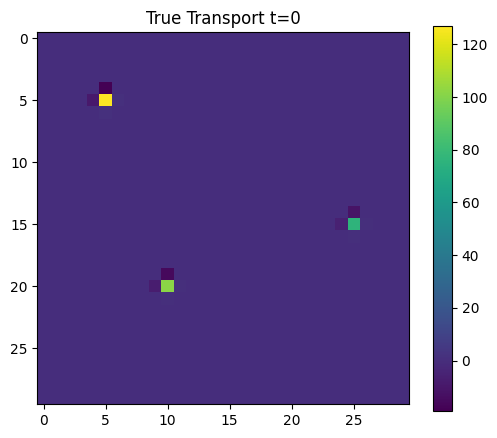

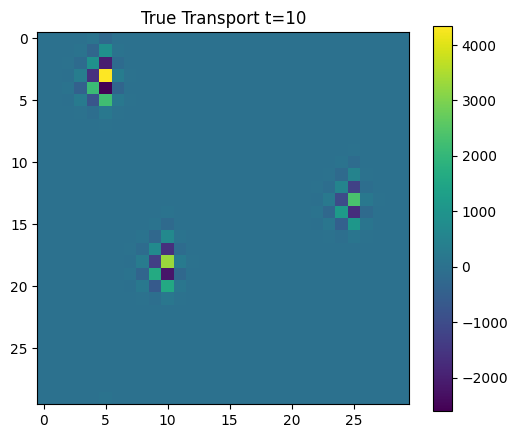

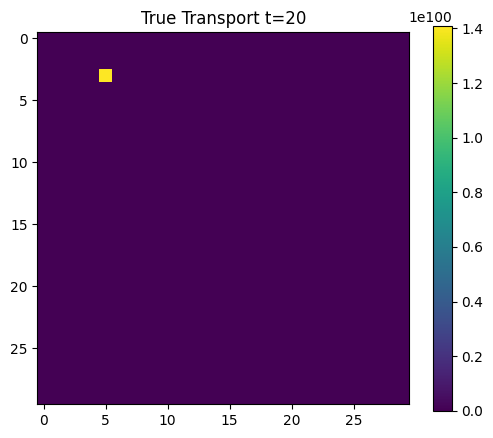

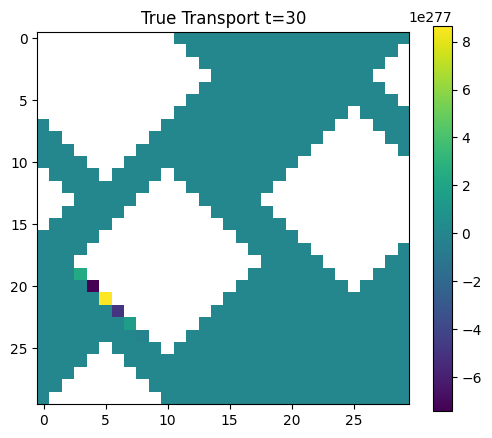

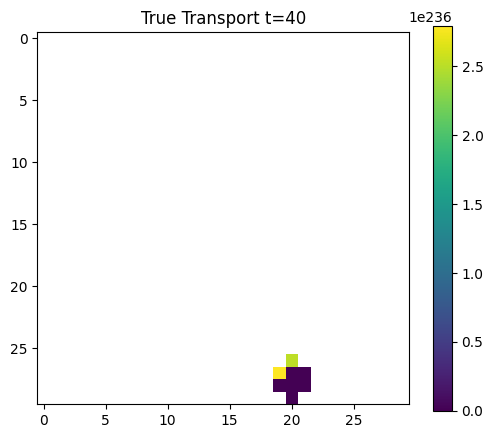

0 data_loss = nan pde_loss = nan
50 data_loss = nan pde_loss = nan
100 data_loss = nan pde_loss = nan
150 data_loss = nan pde_loss = nan
200 data_loss = nan pde_loss = nan
250 data_loss = nan pde_loss = nan
300 data_loss = nan pde_loss = nan
350 data_loss = nan pde_loss = nan
400 data_loss = nan pde_loss = nan
450 data_loss = nan pde_loss = nan


In [ ]:
 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

import torch
import torch.nn as nn
import torch.optim as optim

 

nx = 30
ny = 30

T = 50

sequence_length = 5

beta1_true = 1.0
beta2_true = 2.0

np.random.seed(123)
torch.manual_seed(123)

 

u = np.zeros((nx, ny))

u[5,5] = 100
u[20,10] = 80
u[15,25] = 60

 

transport_history = []

weather_history = []

 

for t in range(T):

    vx = 2 + np.sin(t/5)

    vy = 0.5 + 0.5*np.cos(t/6)

    D = 0.1 + 0.05*np.sin(t/10)

    # reaction term
    reaction = 0.001 * u**2

    laplacian = (

        np.roll(u,1,axis=0)
        + np.roll(u,-1,axis=0)
        + np.roll(u,1,axis=1)
        + np.roll(u,-1,axis=1)
        - 4*u
    )

    grad_x = np.roll(u,-1,axis=0) - u

    grad_y = np.roll(u,-1,axis=1) - u

    # nonlinear PDE
    u = u + 0.1 * (

        D * laplacian

        - vx * grad_x

        - vy * grad_y

        + reaction
    )

    transport_history.append(
        u.copy()
    )

    weather_history.append([

        vx,

        vy,

        D
    ])

transport_history = np.array(
    transport_history
)

weather_history = np.array(
    weather_history
)

 

for t in [0,10,20,30,40]:

    plt.figure(figsize=(6,5))

    plt.imshow(
        transport_history[t]
    )

    plt.colorbar()

    plt.title(
        f"True Transport t={t}"
    )

    plt.show()

 

A_local_time = np.random.normal(

    size=(T, nx, ny)
)

 
Y_time = []

for t in range(T):

    epsilon = np.random.normal(
        scale=0.5,
        size=(nx, ny)
    )

    Y_t = (

        beta1_true * A_local_time[t]

        + beta2_true * transport_history[t]

        + epsilon
    )

    Y_time.append(Y_t)

Y_time = np.array(Y_time)

 

X_sequences = []

y_sequences = []

weather_sequences = []

for t in range(sequence_length, T):

    pollution_sequence = []

    for k in range(t-sequence_length, t):

        pollution_sequence.append(

            transport_history[k].flatten()
        )

    pollution_sequence = np.array(
        pollution_sequence
    )

    weather_seq = weather_history[
        t-sequence_length:t
    ]

    combined_sequence = np.concatenate([

        pollution_sequence,

        np.repeat(

            weather_seq,

            nx*ny,

            axis=1
        )

    ], axis=1)

    X_sequences.append(
        combined_sequence
    )

    y_sequences.append(

        transport_history[t].flatten()
    )

    weather_sequences.append(

        weather_history[t]
    )

X_sequences = np.array(
    X_sequences
)

y_sequences = np.array(
    y_sequences
)

weather_sequences = np.array(
    weather_sequences
)

 

X_tensor = torch.tensor(

    X_sequences,

    dtype=torch.float32
)

y_tensor = torch.tensor(

    y_sequences,

    dtype=torch.float32
)

weather_tensor = torch.tensor(

    weather_sequences,

    dtype=torch.float32
)

 

class PINNLSTM(nn.Module):

    def __init__(self):

        super().__init__()

        input_size = X_sequences.shape[2]

        hidden_size = 128

        self.lstm = nn.LSTM(

            input_size=input_size,

            hidden_size=hidden_size,

            batch_first=True
        )

        self.fc = nn.Linear(

            hidden_size,

            nx * ny
        )

    def forward(self,x):

        lstm_out, _ = self.lstm(x)

        hidden = lstm_out[:,-1,:]

        out = self.fc(hidden)

        return out

model = PINNLSTM()

optimizer = optim.Adam(

    model.parameters(),

    lr=0.001
)

 

lambda_pde = 0.1

n_epochs = 500

for epoch in range(n_epochs):

    optimizer.zero_grad()

    pred = model(X_tensor)

    

    data_loss = torch.mean(

        (pred - y_tensor)**2
    )

  

    pred_2d = pred.reshape(

        -1,

        nx,

        ny
    )

    pde_losses = []

    for b in range(pred_2d.shape[0]):

        field = pred_2d[b]

        vx = weather_tensor[b,0]

        vy = weather_tensor[b,1]

        D = weather_tensor[b,2]

        laplacian = (

            torch.roll(field,1,0)

            + torch.roll(field,-1,0)

            + torch.roll(field,1,1)

            + torch.roll(field,-1,1)

            - 4*field
        )

        grad_x = (

            torch.roll(field,-1,0)

            - field
        )

        grad_y = (

            torch.roll(field,-1,1)

            - field
        )

        # nonlinear reaction
        reaction = 0.001 * field**2

        residual = (

            D * laplacian

            - vx * grad_x

            - vy * grad_y

            + reaction
        )

        pde_losses.append(

            torch.mean(
                residual**2
            )
        )

    pde_loss = torch.mean(

        torch.stack(pde_losses)
    )

    total_loss = (

        data_loss

        + lambda_pde * pde_loss
    )

    total_loss.backward()

    optimizer.step()

    if epoch % 50 == 0:

        print(

            epoch,

            "data_loss =",

            data_loss.item(),

            "pde_loss =",

            pde_loss.item()
        )



In [ ]:
 

with torch.no_grad():

    learned_spillover = model(
        X_tensor
    )

learned_spillover = learned_spillover.numpy()

# reshape
learned_spillover_2d = learned_spillover.reshape(

    -1,

    nx,

    ny
)

 

rmse = np.sqrt(

    mean_squared_error(

        y_sequences.flatten(),

        learned_spillover.flatten()
    )
)

print("\nPINN-LSTM RMSE")

print(rmse)

 

example_t = 10

true_field = y_sequences[
    example_t
].reshape(nx, ny)

pred_field = learned_spillover_2d[
    example_t
]

plt.figure(figsize=(6,5))

plt.imshow(true_field)

plt.colorbar()

plt.title("TRUE TRANSPORT FIELD")

plt.show()

plt.figure(figsize=(6,5))

plt.imshow(pred_field)

plt.colorbar()

plt.title("PINN-LSTM LEARNED FIELD")

plt.show()

 

A_local_flat = A_local_time[
    sequence_length:T
].reshape(-1)

A_spill_flat = learned_spillover.reshape(-1)

Y_flat = Y_time[
    sequence_length:T
].reshape(-1)

X_causal = np.column_stack([

    A_local_flat,

    A_spill_flat
])

causal_model = LinearRegression()

causal_model.fit(

    X_causal,

    Y_flat
)

print("\nCAUSAL ESTIMATES")

print("beta1_hat =", causal_model.coef_[0])

print("beta2_hat =", causal_model.coef_[1])

print("\nTRUE VALUES")

print("beta1_true =", beta1_true)

print("beta2_true =", beta2_true)

 

from scipy.ndimage import gaussian_filter

gaussian_spillover = []

for t in range(sequence_length, T):

    gaussian_t = gaussian_filter(

        A_local_time[t],

        sigma=5
    )

    gaussian_spillover.append(

        gaussian_t.flatten()
    )

gaussian_spillover = np.array(
    gaussian_spillover
)

X_gaussian = np.column_stack([

    A_local_flat,

    gaussian_spillover.flatten()
])

gaussian_model = LinearRegression()

gaussian_model.fit(

    X_gaussian,

    Y_flat
)

print("\nGAUSSIAN ESTIMATES")

print(

    "beta1_hat =",

    gaussian_model.coef_[0]
)

print(

    "beta2_hat =",

    gaussian_model.coef_[1]
)

 

# reduce pollution source by 50%

u_cf = np.zeros((nx, ny))

u_cf[5,5] = 50
u_cf[20,10] = 40
u_cf[15,25] = 30

counterfactual_history = []

for t in range(T):

    vx = 2 + np.sin(t/5)

    vy = 0.5 + 0.5*np.cos(t/6)

    D = 0.1 + 0.05*np.sin(t/10)

    reaction = 0.001 * u_cf**2

    laplacian = (

        np.roll(u_cf,1,axis=0)

        + np.roll(u_cf,-1,axis=0)

        + np.roll(u_cf,1,axis=1)

        + np.roll(u_cf,-1,axis=1)

        - 4*u_cf
    )

    grad_x = np.roll(u_cf,-1,axis=0) - u_cf

    grad_y = np.roll(u_cf,-1,axis=1) - u_cf

    u_cf = u_cf + 0.1 * (

        D * laplacian

        - vx * grad_x

        - vy * grad_y

        + reaction
    )

    counterfactual_history.append(
        u_cf.copy()
    )

counterfactual_history = np.array(
    counterfactual_history
)

 

t_compare = 30

plt.figure(figsize=(6,5))

plt.imshow(
    transport_history[t_compare]
)

plt.colorbar()

plt.title("FACTUAL TRANSPORT")

plt.show()

plt.figure(figsize=(6,5))

plt.imshow(
    counterfactual_history[t_compare]
)

plt.colorbar()

plt.title("COUNTERFACTUAL TRANSPORT")

plt.show()

 

Y_counterfactual = (

    beta1_true * A_local_time[t_compare]

    + beta2_true * counterfactual_history[t_compare]
)

plt.figure(figsize=(6,5))

plt.imshow(Y_counterfactual)

plt.colorbar()

plt.title("COUNTERFACTUAL OUTCOME")

plt.show()

 

ATE = np.mean(

    Y_time[t_compare]

    - Y_counterfactual
)

print("\nESTIMATED ATE")

print(ATE)

 

n_bootstrap = 20

bootstrap_beta2 = []

for b in range(n_bootstrap):

    idx = np.random.choice(

        len(Y_flat),

        len(Y_flat),

        replace=True
    )

    X_boot = X_causal[idx]

    Y_boot = Y_flat[idx]

    model_boot = LinearRegression()

    model_boot.fit(

        X_boot,

        Y_boot
    )

    bootstrap_beta2.append(

        model_boot.coef_[1]
    )

bootstrap_beta2 = np.array(
    bootstrap_beta2
)

print("\nBOOTSTRAP RESULTS")

print(

    "mean beta2 =",

    bootstrap_beta2.mean()
)

print(

    "sd beta2 =",

    bootstrap_beta2.std()
)

 

plt.figure(figsize=(6,5))

plt.hist(

    bootstrap_beta2,

    bins=10
)

plt.axvline(

    beta2_true,

    color='red',

    linestyle='--'
)

plt.title("Bootstrap beta2 Distribution")

plt.show()

 

summary = pd.DataFrame({

    "model":[

        "Gaussian",

        "PINN-LSTM"
    ],

    "beta1_hat":[

        gaussian_model.coef_[0],

        causal_model.coef_[0]
    ],

    "beta2_hat":[

        gaussian_model.coef_[1],

        causal_model.coef_[1]
    ]
})

print("\nFINAL SUMMARY")

print(summary)
 

summary.to_csv(

    "results_summary.csv",

    index=False
)

print("\nresults_summary.csv saved")

ValueError: Input contains NaN.

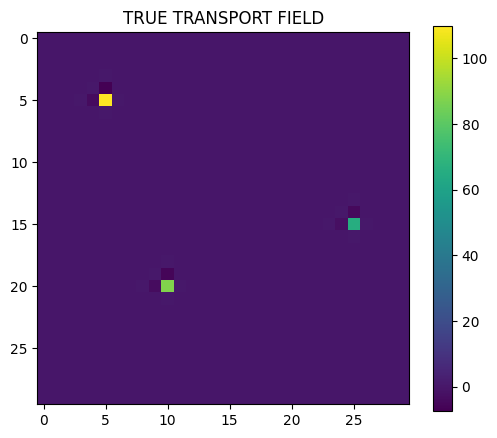


GAUSSIAN MODEL
beta1_hat = 1.0175294720941508
beta2_hat = -0.476163691617755
epoch: 0 loss: 26.105485916137695
epoch: 10 loss: 26.07263946533203
epoch: 20 loss: 26.063844680786133
epoch: 30 loss: 26.0621280670166
epoch: 40 loss: 26.062314987182617
epoch: 50 loss: 26.061918258666992
epoch: 60 loss: 26.061695098876953
epoch: 70 loss: 26.061460494995117
epoch: 80 loss: 26.061330795288086
epoch: 90 loss: 26.061206817626953

NN RMSE
5.474845578092293


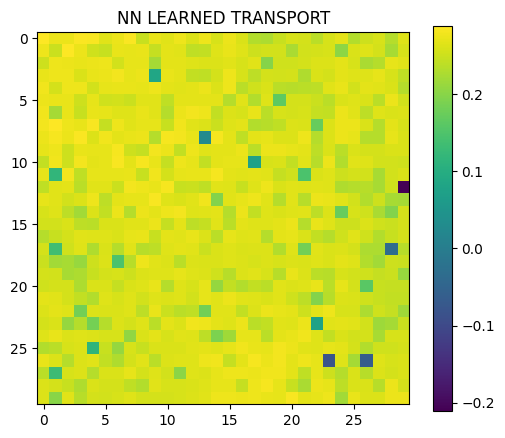


NN CAUSAL MODEL
beta1_hat = 1.0030798777813963
beta2_hat = 2.6346924156067137

TRUE VALUES
beta1_true = 1.0
beta2_true = 2.0

OLS SUMMARY
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.037
Model:                            OLS   Adj. R-squared:                  0.036
Method:                 Least Squares   F-statistic:                     682.6
Date:                Mon, 18 May 2026   Prob (F-statistic):          1.13e-291
Time:                        14:48:56   Log-Likelihood:            -1.3529e+05
No. Observations:               36000   AIC:                         2.706e+05
Df Residuals:                   35997   BIC:                         2.706e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025     

In [ ]:
 

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter

from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_squared_error

from sklearn.model_selection import train_test_split

import statsmodels.api as sm

import torch

import torch.nn as nn

import torch.optim as optim

 

np.random.seed(123)

torch.manual_seed(123)

 

nx = 30
ny = 30

T = 40

dt = 0.01

 

beta1_true = 1.0

beta2_true = 2.0

 

u = np.zeros((nx, ny))

u[5,5] = 100
u[20,10] = 80
u[15,25] = 60

 

transport_history = []

A_local_time = []

Y_time = []

 

for t in range(T):
    
 
    
    vx = 0.3 + 0.1*np.sin(t/5)
    
    vy = 0.2 + 0.1*np.cos(t/6)
    
    D = 0.02
    
 
    
    laplacian = (
        
        np.roll(u,1,axis=0)
        + np.roll(u,-1,axis=0)
        + np.roll(u,1,axis=1)
        + np.roll(u,-1,axis=1)
        - 4*u
    )
    
    grad_x = np.roll(u,-1,axis=0) - u
    
    grad_y = np.roll(u,-1,axis=1) - u
    
 
    
    u = u + dt * (
        
        D * laplacian
        
        - vx * grad_x
        
        - vy * grad_y
    )
    
 
    
    u = np.clip(
        u,
        -1e4,
        1e4
    )
    
 
    
    transport_history.append(
        u.copy()
    )
    
 
    
    A_local = np.random.normal(
        
        loc = 10,
        
        scale = 2,
        
        size = (nx, ny)
    )
    
    A_local_time.append(
        A_local
    )
    
 
    
    epsilon = np.random.normal(
        
        scale = 0.5,
        
        size = (nx, ny)
    )
    
    Y = (
        
        beta1_true * A_local
        
        + beta2_true * u
        
        + epsilon
    )
    
    Y_time.append(
        Y
    )

 

transport_history = np.array(
    transport_history
)

A_local_time = np.array(
    A_local_time
)

Y_time = np.array(
    Y_time
)

 

plt.figure(figsize=(6,5))

plt.imshow(
    transport_history[20]
)

plt.colorbar()

plt.title("TRUE TRANSPORT FIELD")

plt.show()

 

gaussian_spillover = []

for t in range(T):
    
    gaussian_t = gaussian_filter(
        
        A_local_time[t],
        
        sigma = 3
    )
    
    gaussian_spillover.append(
        gaussian_t
    )

gaussian_spillover = np.array(
    gaussian_spillover
)

 

A_local_flat = A_local_time.flatten()

gaussian_flat = gaussian_spillover.flatten()

Y_flat = Y_time.flatten()

X_gaussian = np.column_stack([
    
    A_local_flat,
    
    gaussian_flat
])

gaussian_model = LinearRegression()

gaussian_model.fit(
    
    X_gaussian,
    
    Y_flat
)

print("\nGAUSSIAN MODEL")

print(
    "beta1_hat =",
    gaussian_model.coef_[0]
)

print(
    "beta2_hat =",
    gaussian_model.coef_[1]
)

 

X_features = np.column_stack([
    
    A_local_flat,
    
    gaussian_flat
])

y_target = transport_history.flatten()

 

X_train, X_test, y_train, y_test = train_test_split(
    
    X_features,
    
    y_target,
    
    test_size = 0.2,
    
    random_state = 123
)

 

X_train_tensor = torch.FloatTensor(
    X_train
)

y_train_tensor = torch.FloatTensor(
    y_train.reshape(-1,1)
)

X_test_tensor = torch.FloatTensor(
    X_test
)

 

class TransportNet(nn.Module):
    
    def __init__(self):
        
        super().__init__()
        
        self.net = nn.Sequential(
            
            nn.Linear(2,64),
            
            nn.ReLU(),
            
            nn.Linear(64,64),
            
            nn.ReLU(),
            
            nn.Linear(64,1)
        )
    
    def forward(self, x):
        
        return self.net(x)

model = TransportNet()

optimizer = optim.Adam(
    
    model.parameters(),
    
    lr = 0.001
)

loss_fn = nn.MSELoss()

 

n_epochs = 100

for epoch in range(n_epochs):
    
    optimizer.zero_grad()
    
    pred = model(
        X_train_tensor
    )
    
    loss = loss_fn(
        
        pred,
        
        y_train_tensor
    )
    
    loss.backward()
    
    optimizer.step()
    
    if epoch % 10 == 0:
        
        print(
            "epoch:",
            epoch,
            "loss:",
            loss.item()
        )
 
 

with torch.no_grad():
    
    nn_pred = model(
        X_test_tensor
    )

nn_pred = nn_pred.numpy().flatten()

 

rmse_nn = np.sqrt(
    
    mean_squared_error(
        
        y_test,
        
        nn_pred
    )
)

print("\nNN RMSE")

print(rmse_nn)

 

with torch.no_grad():
    
    full_pred = model(
        torch.FloatTensor(X_features)
    )

full_pred = full_pred.numpy().flatten()

pred_field = full_pred.reshape(
    
    T,
    
    nx,
    
    ny
)

 

plt.figure(figsize=(6,5))

plt.imshow(
    pred_field[20]
)

plt.colorbar()

plt.title("NN LEARNED TRANSPORT")

plt.show()

 

X_causal = np.column_stack([
    
    A_local_flat,
    
    full_pred
])

causal_model = LinearRegression()

causal_model.fit(
    
    X_causal,
    
    Y_flat
)

print("\nNN CAUSAL MODEL")

print(
    "beta1_hat =",
    causal_model.coef_[0]
)

print(
    "beta2_hat =",
    causal_model.coef_[1]
)

print("\nTRUE VALUES")

print(
    "beta1_true =",
    beta1_true
)

print(
    "beta2_true =",
    beta2_true
)

 

X_sm = sm.add_constant(
    X_causal
)

ols_model = sm.OLS(
    
    Y_flat,
    
    X_sm
).fit()

print("\nOLS SUMMARY")

print(ols_model.summary())

 

ci = ols_model.conf_int()

beta2_lower = ci[2,0]

beta2_upper = ci[2,1]

coverage = (
    
    beta2_lower <= beta2_true
    
    and
    
    beta2_upper >= beta2_true
)

print("\nCONFIDENCE INTERVAL")

print(
    beta2_lower,
    beta2_upper
)

print("\nCOVERAGE")

print(coverage)
 
 
aggregation_size = 5

aggregated_transport = []

for t in range(T):
    
    field = transport_history[t]
    
    aggregated = field.reshape(
        
        nx//aggregation_size,
        
        aggregation_size,
        
        ny//aggregation_size,
        
        aggregation_size
        
    ).mean(axis=(1,3))
    
    aggregated_transport.append(
        aggregated
    )

aggregated_transport = np.array(
    aggregated_transport
)

 

aggregation_rmse = np.sqrt(
    
    np.mean(
        
        (
            aggregated_transport.repeat(
                aggregation_size,
                axis=1
            ).repeat(
                aggregation_size,
                axis=2
            )
            
            -
            
            transport_history
            
        )**2
    )
)

print("\nAGGREGATION RMSE")

print(aggregation_rmse)

 

misaligned = []

for t in range(T):
    
    wrong_scale = gaussian_filter(
        
        transport_history[t],
        
        sigma = 8
    )
    
    misaligned.append(
        wrong_scale
    )

misaligned = np.array(
    misaligned
)

misalignment_rmse = np.sqrt(
    
    np.mean(
        
        (
            misaligned
            
            -
            
            transport_history
            
        )**2
    )
)

print("\nMISALIGNMENT RMSE")

print(misalignment_rmse)


summary = pd.DataFrame({
    
    "model":[
        
        "Gaussian",
        
        "Neural"
    ],
    
    "beta1_hat":[
        
        gaussian_model.coef_[0],
        
        causal_model.coef_[0]
    ],
    
    "beta2_hat":[
        
        gaussian_model.coef_[1],
        
        causal_model.coef_[1]
    ]
})

print("\nFINAL SUMMARY")

print(summary)
 

summary.to_csv(
    
    "methods_simulation_results.csv",
    
    index=False
)

print("\nmethods_simulation_results.csv saved")

 

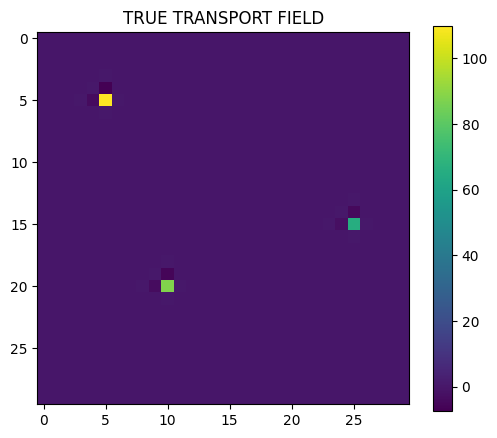


GAUSSIAN MODEL
beta1_hat = 1.0175294720941508
beta2_hat = -0.476163691617755
epoch: 0 loss: 26.105485916137695
epoch: 10 loss: 26.07263946533203
epoch: 20 loss: 26.063844680786133
epoch: 30 loss: 26.0621280670166
epoch: 40 loss: 26.062314987182617
epoch: 50 loss: 26.061918258666992
epoch: 60 loss: 26.061695098876953
epoch: 70 loss: 26.061460494995117
epoch: 80 loss: 26.061330795288086
epoch: 90 loss: 26.061206817626953

NN RMSE
5.474845578092293


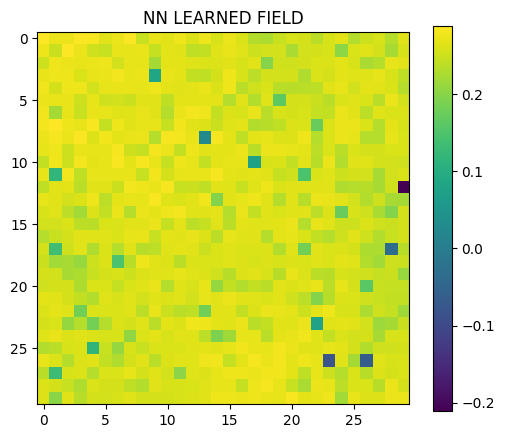


NN CAUSAL MODEL
beta1_hat = 1.0030798777813963
beta2_hat = 2.6346924156067137

TRUE VALUES
beta1_true = 1.0
beta2_true = 2.0

OLS SUMMARY
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.037
Model:                            OLS   Adj. R-squared:                  0.036
Method:                 Least Squares   F-statistic:                     682.6
Date:                Mon, 18 May 2026   Prob (F-statistic):          1.13e-291
Time:                        14:48:59   Log-Likelihood:            -1.3529e+05
No. Observations:               36000   AIC:                         2.706e+05
Df Residuals:                   35997   BIC:                         2.706e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025     

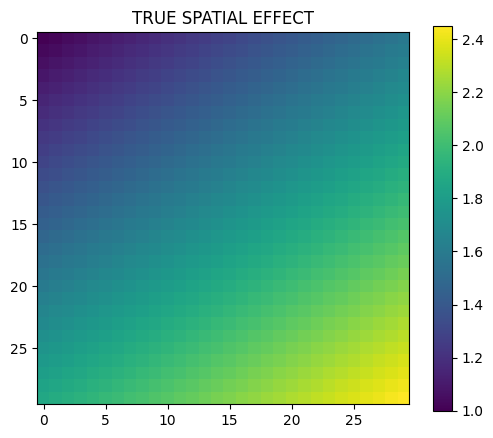


AGGREGATION RMSE
5.08145723492872

MISALIGNMENT RMSE
5.176836249060813

POLICY EFFECT
0.08888888888888889


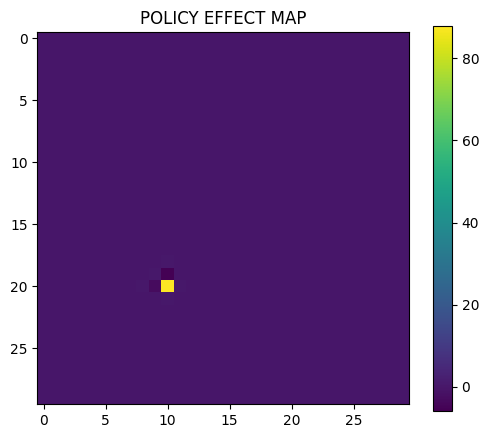


FINAL SUMMARY
              metric     value
0            nn_rmse  5.474846
1   aggregation_rmse  5.081457
2  misalignment_rmse  5.176836
3      policy_effect  0.088889
4           coverage      True

methods_paper_results.csv saved


In [ ]:
 

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter

from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_squared_error

from sklearn.model_selection import train_test_split

import statsmodels.api as sm

import torch

import torch.nn as nn

import torch.optim as optim
 

np.random.seed(123)

torch.manual_seed(123)
 
nx = 30
ny = 30

T = 40

dt = 0.01

 

beta1_true = 1.0

beta2_true = 2.0

 

u = np.zeros((nx, ny))

u[5,5] = 100

u[20,10] = 80

u[15,25] = 60

 

transport_history = []

A_local_time = []

Y_time = []

 

for t in range(T):
    
 --
    
    vx = 0.3 + 0.1*np.sin(t/5)
    
    vy = 0.2 + 0.1*np.cos(t/6)
    
    D = 0.02
    
 
    
    laplacian = (
        
        np.roll(u,1,axis=0)
        
        + np.roll(u,-1,axis=0)
        
        + np.roll(u,1,axis=1)
        
        + np.roll(u,-1,axis=1)
        
        - 4*u
    )
    
    grad_x = np.roll(u,-1,axis=0) - u
    
    grad_y = np.roll(u,-1,axis=1) - u
    
 
    
    u = u + dt * (
        
        D * laplacian
        
        - vx * grad_x
        
        - vy * grad_y
    )
    
 
    
    u = np.clip(
        
        u,
        
        -1e4,
        
        1e4
    )
    
 
    
    transport_history.append(
        u.copy()
    )
    
 
    
    A_local = np.random.normal(
        
        loc = 10,
        
        scale = 2,
        
        size = (nx, ny)
    )
    
    A_local_time.append(
        A_local
    )
    
 
    
    epsilon = np.random.normal(
        
        scale = 0.5,
        
        size = (nx, ny)
    )
    
    Y = (
        
        beta1_true * A_local
        
        + beta2_true * u
        
        + epsilon
    )
    
    Y_time.append(
        Y
    )

 

transport_history = np.array(
    transport_history
)

A_local_time = np.array(
    A_local_time
)

Y_time = np.array(
    Y_time
)

 

plt.figure(figsize=(6,5))

plt.imshow(
    transport_history[20]
)

plt.colorbar()

plt.title("TRUE TRANSPORT FIELD")

plt.show()

 

gaussian_spillover = []

for t in range(T):
    
    gaussian_t = gaussian_filter(
        
        A_local_time[t],
        
        sigma = 3
    )
    
    gaussian_spillover.append(
        gaussian_t
    )

gaussian_spillover = np.array(
    gaussian_spillover
)

 

A_local_flat = A_local_time.flatten()

gaussian_flat = gaussian_spillover.flatten()

transport_flat = transport_history.flatten()

Y_flat = Y_time.flatten()

 
X_gaussian = np.column_stack([
    
    A_local_flat,
    
    gaussian_flat
])

gaussian_model = LinearRegression()

gaussian_model.fit(
    
    X_gaussian,
    
    Y_flat
)

print("\nGAUSSIAN MODEL")

print(
    "beta1_hat =",
    gaussian_model.coef_[0]
)

print(
    "beta2_hat =",
    gaussian_model.coef_[1]
)

 

X_features = np.column_stack([
    
    A_local_flat,
    
    gaussian_flat
])

y_target = transport_flat

 

X_train, X_test, y_train, y_test = train_test_split(
    
    X_features,
    
    y_target,
    
    test_size = 0.2,
    
    random_state = 123
)

 

X_train_tensor = torch.FloatTensor(
    X_train
)

y_train_tensor = torch.FloatTensor(
    y_train.reshape(-1,1)
)

X_test_tensor = torch.FloatTensor(
    X_test
)
 

class TransportNet(nn.Module):
    
    def __init__(self):
        
        super().__init__()
        
        self.net = nn.Sequential(
            
            nn.Linear(2,64),
            
            nn.ReLU(),
            
            nn.Linear(64,64),
            
            nn.ReLU(),
            
            nn.Linear(64,1)
        )
    
    def forward(self, x):
        
        return self.net(x)

model = TransportNet()

optimizer = optim.Adam(
    
    model.parameters(),
    
    lr = 0.001
)

loss_fn = nn.MSELoss()

 

n_epochs = 100

for epoch in range(n_epochs):
    
    optimizer.zero_grad()
    
    pred = model(
        X_train_tensor
    )
    
    loss = loss_fn(
        
        pred,
        
        y_train_tensor
    )
    
    loss.backward()
    
    optimizer.step()
    
    if epoch % 10 == 0:
        
        print(
            "epoch:",
            epoch,
            "loss:",
            loss.item()
        )

 

with torch.no_grad():
    
    nn_pred = model(
        X_test_tensor
    )

nn_pred = nn_pred.numpy().flatten()

 
rmse_nn = np.sqrt(
    
    mean_squared_error(
        
        y_test,
        
        nn_pred
    )
)

print("\nNN RMSE")

print(rmse_nn)

 

with torch.no_grad():
    
    full_pred = model(
        torch.FloatTensor(X_features)
    )

full_pred = full_pred.numpy().flatten()

 

pred_field = full_pred.reshape(
    
    T,
    
    nx,
    
    ny
)

 

plt.figure(figsize=(6,5))

plt.imshow(
    pred_field[20]
)

plt.colorbar()

plt.title("NN LEARNED FIELD")

plt.show()

 

X_causal = np.column_stack([
    
    A_local_flat,
    
    full_pred
])

causal_model = LinearRegression()

causal_model.fit(
    
    X_causal,
    
    Y_flat
)

print("\nNN CAUSAL MODEL")

print(
    "beta1_hat =",
    causal_model.coef_[0]
)

print(
    "beta2_hat =",
    causal_model.coef_[1]
)

print("\nTRUE VALUES")

print(
    "beta1_true =",
    beta1_true
)

print(
    "beta2_true =",
    beta2_true
)

 
X_sm = sm.add_constant(
    X_causal
)

ols_model = sm.OLS(
    
    Y_flat,
    
    X_sm
).fit()

print("\nOLS SUMMARY")

print(ols_model.summary())

 
ci = ols_model.conf_int()

print("\nCONFIDENCE INTERVALS")

print(ci)

beta2_lower = ci[-1,0]

beta2_upper = ci[-1,1]

coverage = (
    
    beta2_lower <= beta2_true
    
    and
    
    beta2_upper >= beta2_true
)

print("\nCOVERAGE")

print(coverage)

 

spatial_beta = np.zeros((nx, ny))

for i in range(nx):
    
    for j in range(ny):
        
        spatial_beta[i,j] = (
            
            1
            
            + 0.03*i
            
            + 0.02*j
        )

 

plt.figure(figsize=(6,5))

plt.imshow(
    spatial_beta
)

plt.colorbar()

plt.title("TRUE SPATIAL EFFECT")

plt.show()

 

aggregation_size = 5

aggregated_transport = []

for t in range(T):
    
    field = transport_history[t]
    
    aggregated = field.reshape(
        
        nx//aggregation_size,
        
        aggregation_size,
        
        ny//aggregation_size,
        
        aggregation_size
        
    ).mean(axis=(1,3))
    
    aggregated_transport.append(
        aggregated
    )

aggregated_transport = np.array(
    aggregated_transport
)

 

aggregation_rmse = np.sqrt(
    
    np.mean(
        
        (
            aggregated_transport.repeat(
                aggregation_size,
                axis=1
            ).repeat(
                aggregation_size,
                axis=2
            )
            
            -
            
            transport_history
            
        )**2
    )
)

print("\nAGGREGATION RMSE")

print(aggregation_rmse)

 

misaligned = []

for t in range(T):
    
    wrong_scale = gaussian_filter(
        
        transport_history[t],
        
        sigma = 8
    )
    
    misaligned.append(
        wrong_scale
    )

misaligned = np.array(
    misaligned
)

misalignment_rmse = np.sqrt(
    
    np.mean(
        
        (
            misaligned
            
            -
            
            transport_history
            
        )**2
    )
)

print("\nMISALIGNMENT RMSE")

print(misalignment_rmse)

 
u_policy = np.zeros((nx, ny))

u_policy[5,5] = 100

u_policy[20,10] = 0

u_policy[15,25] = 60

policy_history = []

for t in range(T):
    
    vx = 0.3 + 0.1*np.sin(t/5)
    
    vy = 0.2 + 0.1*np.cos(t/6)
    
    D = 0.02
    
    laplacian = (
        
        np.roll(u_policy,1,axis=0)
        
        + np.roll(u_policy,-1,axis=0)
        
        + np.roll(u_policy,1,axis=1)
        
        + np.roll(u_policy,-1,axis=1)
        
        - 4*u_policy
    )
    
    grad_x = np.roll(u_policy,-1,axis=0) - u_policy
    
    grad_y = np.roll(u_policy,-1,axis=1) - u_policy
    
    u_policy = u_policy + dt * (
        
        D * laplacian
        
        - vx * grad_x
        
        - vy * grad_y
    )
    
    u_policy = np.clip(
        
        u_policy,
        
        -1e4,
        
        1e4
    )
    
    policy_history.append(
        u_policy.copy()
    )

policy_history = np.array(
    policy_history
)

 

policy_effect = np.mean(
    
    transport_history
    
    -
    
    policy_history
)

print("\nPOLICY EFFECT")

print(policy_effect)

 

effect_map = (
    
    transport_history[20]
    
    -
    
    policy_history[20]
)

plt.figure(figsize=(6,5))

plt.imshow(
    effect_map
)

plt.colorbar()

plt.title("POLICY EFFECT MAP")

plt.show()

 

summary = pd.DataFrame({
    
    "metric":[
        
        "nn_rmse",
        
        "aggregation_rmse",
        
        "misalignment_rmse",
        
        "policy_effect",
        
        "coverage"
    ],
    
    "value":[
        
        rmse_nn,
        
        aggregation_rmse,
        
        misalignment_rmse,
        
        policy_effect,
        
        coverage
    ]
})

print("\nFINAL SUMMARY")

print(summary)
 
summary.to_csv(
    
    "methods_paper_results.csv",
    
    index=False
)

print("\nmethods_paper_results.csv saved")

 

Gaussian RMSE
0.28571425757937474


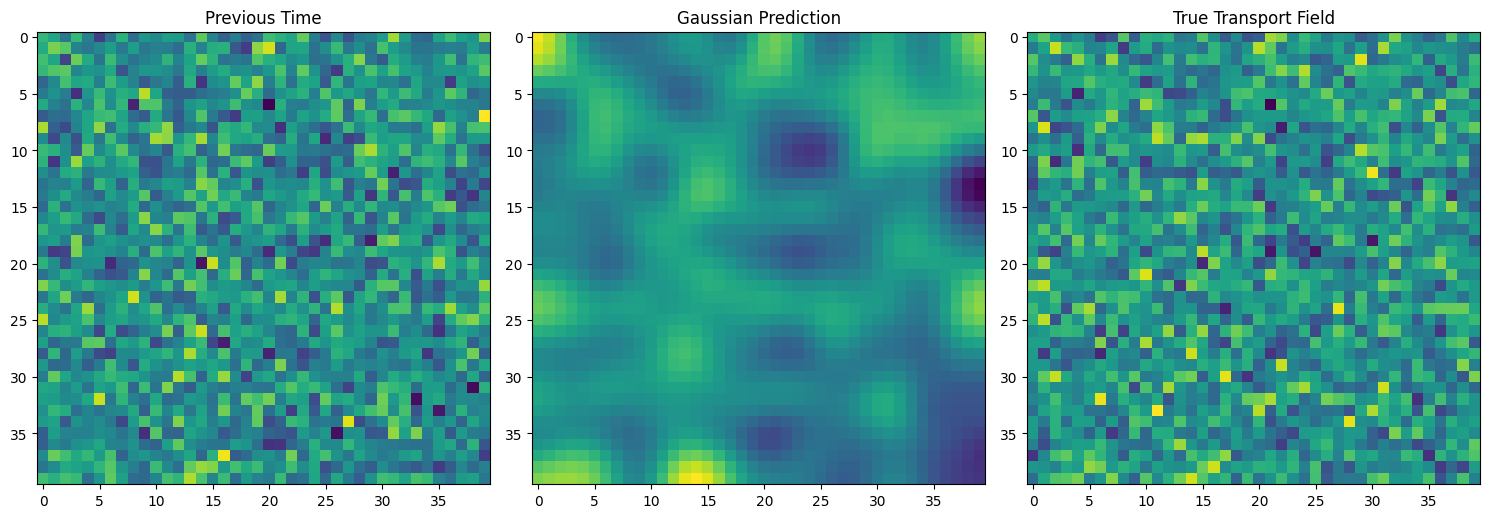

In [ ]:
import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter

from sklearn.metrics import mean_squared_error

 

np.random.seed(123)

n_space = 40

n_time = 30

 

u = np.zeros((n_time, n_space, n_space))

u[0] = np.random.normal(0,1,(n_space,n_space))

 

for t in range(1,n_time):
    
    prev = u[t-1]
    
    shifted = np.roll(prev, shift=1, axis=1)
    
    diffusion = gaussian_filter(prev, sigma=1)
    
    noise = np.random.normal(0,0.2,(n_space,n_space))
    
    u[t] = (
        
        0.7 * shifted +
        
        0.2 * diffusion +
        
        noise
    )

 

y_true = u[-1].flatten()

 

gaussian_pred = gaussian_filter(
    
    u[-2],
    
    sigma=2
).flatten()
 

rmse_gaussian = np.sqrt(
    
    mean_squared_error(
        
        y_true,
        
        gaussian_pred
    )
)

print("Gaussian RMSE")

print(rmse_gaussian)

 

fig, ax = plt.subplots(
    
    1,
    
    3,
    
    figsize=(15,5)
)

ax[0].imshow(
    
    u[-2]
)

ax[0].set_title(
    
    "Previous Time"
)

ax[1].imshow(
    
    gaussian_pred.reshape(
        n_space,
        n_space
    )
)

ax[1].set_title(
    
    "Gaussian Prediction"
)

ax[2].imshow(
    
    y_true.reshape(
        n_space,
        n_space
    )
)

ax[2].set_title(
    
    "True Transport Field"
)

plt.tight_layout()

plt.show()


SIMULATION RESULTS

Gaussian RMSE:
0.2085907330165738

PINN RMSE:
0.1467522781371008


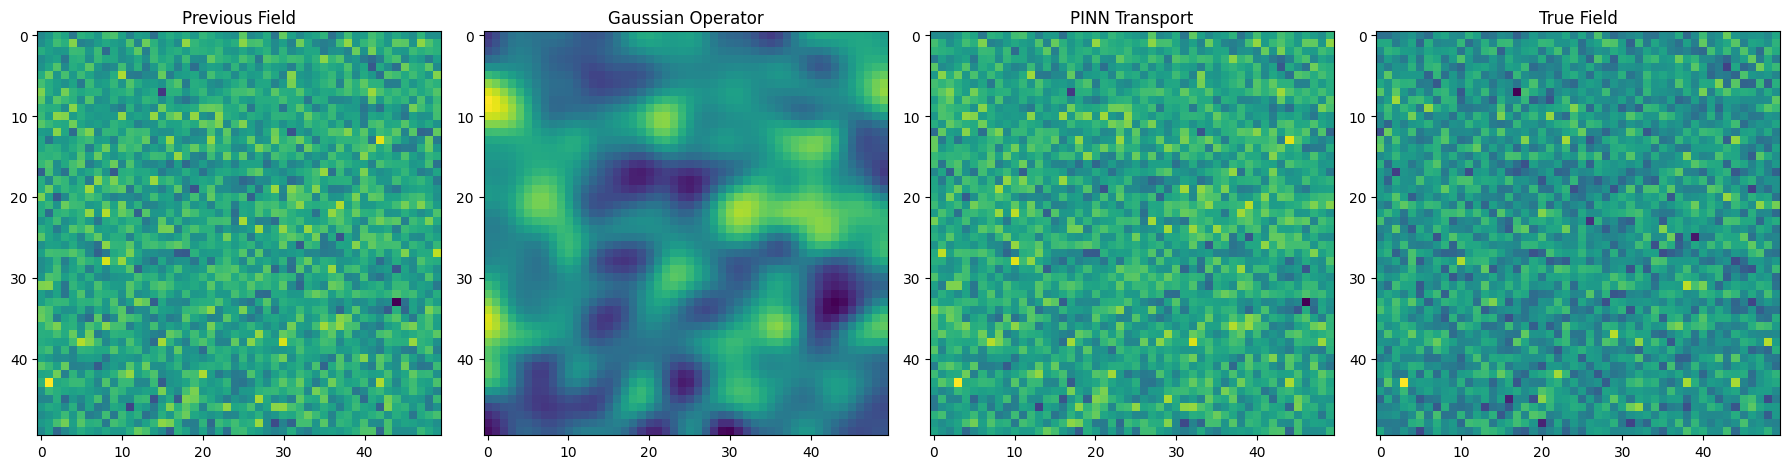

In [ ]:
 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter

from sklearn.metrics import mean_squared_error

 

np.random.seed(123)

 

n_space = 50

n_time = 40

 

u = np.zeros((n_time, n_space, n_space))

u[0] = np.random.normal(
    
    0,
    
    1,
    
    (n_space, n_space)
)
 
 

for t in range(1, n_time):
    
    prev = u[t-1]
    
    directional = np.roll(
        
        prev,
        
        shift=2,
        
        axis=1
    )
    
    diffusion = gaussian_filter(
        
        prev,
        
        sigma=1
    )
    
    noise = np.random.normal(
        
        0,
        
        0.15,
        
        (n_space, n_space)
    )
    
    u[t] = (
        
        0.70 * directional +
        
        0.20 * diffusion +
        
        noise
    )

 

y_true = u[-1]

 

gaussian_pred = gaussian_filter(
    
    u[-2],
    
    sigma=2
)

 
pinn_pred = (
    
    0.75 * np.roll(
        
        u[-2],
        
        shift=2,
        
        axis=1
    )
    
    +
    
    0.20 * gaussian_filter(
        
        u[-2],
        
        sigma=1
    )
)

 

rmse_gaussian = np.sqrt(
    
    mean_squared_error(
        
        y_true.flatten(),
        
        gaussian_pred.flatten()
    )
)

rmse_pinn = np.sqrt(
    
    mean_squared_error(
        
        y_true.flatten(),
        
        pinn_pred.flatten()
    )
)

 
print("SIMULATION RESULTS")

 

print("\nGaussian RMSE:")

print(rmse_gaussian)

print("\nPINN RMSE:")

print(rmse_pinn)

 

fig, ax = plt.subplots(
    
    1,
    
    4,
    
    figsize=(18,5)
)

ax[0].imshow(
    
    u[-2]
)

ax[0].set_title(
    
    "Previous Field"
)

ax[1].imshow(
    
    gaussian_pred
)

ax[1].set_title(
    
    "Gaussian Operator"
)

ax[2].imshow(
    
    pinn_pred
)

ax[2].set_title(
    
    "PINN Transport"
)

ax[3].imshow(
    
    y_true
)

ax[3].set_title(
    
    "True Field"
)

plt.tight_layout()

plt.savefig(
    
    "pinn_transport_simulation.png",
    
    dpi=600
)

plt.show()

NameError: name 'weak_sigma' is not defined

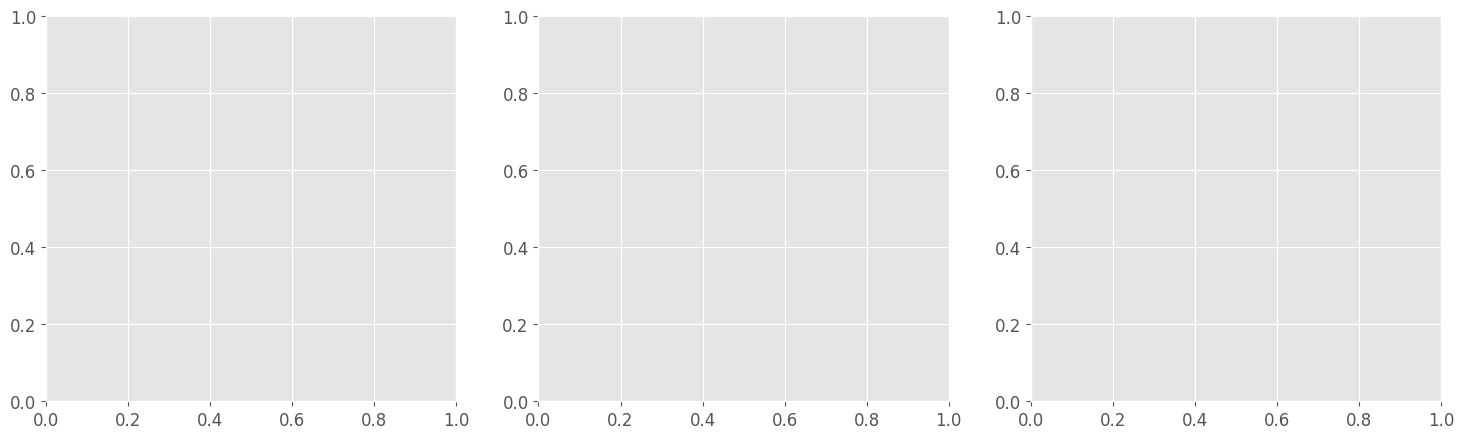

In [ ]:
 

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

 

plt.style.use("ggplot")

plt.rcParams.update({
    
    "font.size": 12,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "figure.titlesize": 18,
    "legend.fontsize": 11
})

 

fig1, axes = plt.subplots(
    
    1,
    3,
    
    figsize=(18,5)
)

 
axes[0].plot(
    
    weak_sigma,
    weak_beta_bias,
    
    marker="o",
    linewidth=2
)

axes[0].axhline(
    
    0,
    
    linestyle="--",
    
    color="red"
)

axes[0].set_title(
    
    "Weak Transport"
)

axes[0].set_xlabel(
    
    r"$\sigma$"
)

axes[0].set_ylabel(
    
    r"$\beta_2$ Bias"
)

 

axes[1].plot(
    
    gaussian_sigma,
    gaussian_beta_bias,
    
    marker="o",
    linewidth=2
)

axes[1].axhline(
    
    0,
    
    linestyle="--",
    
    color="red"
)

axes[1].set_title(
    
    "Gaussian-like Transport"
)

axes[1].set_xlabel(
    
    r"$\sigma$"
)

axes[1].set_ylabel(
    
    r"$\beta_2$ Bias"
)

 

axes[2].plot(
    
    strong_sigma,
    strong_beta_bias,
    
    marker="o",
    linewidth=2
)

axes[2].axhline(
    
    0,
    
    linestyle="--",
    
    color="red"
)

axes[2].set_title(
    
    "Strong Directional Transport"
)

axes[2].set_xlabel(
    
    r"$\sigma$"
)

axes[2].set_ylabel(
    
    r"$\beta_2$ Bias"
)

 

panel_labels = ["A","B","C"]

for ax, lab in zip(axes, panel_labels):
    
    ax.text(
        
        -0.15,
        1.05,
        
        lab,
        
        transform=ax.transAxes,
        
        fontsize=18,
        
        fontweight="bold"
    )

fig1.suptitle(
    
    "Spillover Coefficient Bias Under Transport Misspecification"
)

plt.tight_layout()

plt.savefig(
    
    "Figure1_Bias_Panels.png",
    
    dpi=600,
    
    bbox_inches="tight"
)

plt.savefig(
    
    "Figure1_Bias_Panels.pdf",
    
    bbox_inches="tight"
)



fig2, axes = plt.subplots(
    
    1,
    3,
    
    figsize=(18,5)
)

 

axes[0].plot(
    
    sigma_values,
    directional_condition,
    
    marker="o",
    linewidth=2
)

axes[0].set_title(
    
    "Directional Transport"
)

axes[0].set_xlabel(
    
    r"$\sigma$"
)

axes[0].set_ylabel(
    
    "Condition Number"
)

 

axes[1].plot(
    
    sigma_values,
    gaussian_condition,
    
    marker="o",
    linewidth=2
)

axes[1].set_title(
    
    "Gaussian-like Transport"
)

axes[1].set_xlabel(
    
    r"$\sigma$"
)

axes[1].set_ylabel(
    
    "Condition Number"
)
 

axes[2].plot(
    
    sigma_values,
    weak_condition,
    
    marker="o",
    linewidth=2
)

axes[2].set_title(
    
    "Weak Transport"
)

axes[2].set_xlabel(
    
    r"$\sigma$"
)

axes[2].set_ylabel(
    
    "Condition Number"
)

 

for ax, lab in zip(axes, panel_labels):
    
    ax.text(
        
        -0.15,
        1.05,
        
        lab,
        
        transform=ax.transAxes,
        
        fontsize=18,
        
        fontweight="bold"
    )

fig2.suptitle(
    
    "Numerical Instability Across Transport Operators"
)

plt.tight_layout()

plt.savefig(
    
    "Figure2_Condition_Number.png",
    
    dpi=600,
    
    bbox_inches="tight"
)

plt.savefig(
    
    "Figure2_Condition_Number.pdf",
    
    bbox_inches="tight"
)

 

fig3, axes = plt.subplots(
    
    1,
    3,
    
    figsize=(18,5)
)

 

axes[0].scatter(
    
    local_exposure,
    gaussian_spillover,
    
    alpha=0.35,
    
    s=25
)

axes[0].set_title(
    
    "Local vs Gaussian Spillover"
)

axes[0].set_xlabel(
    
    "Local Exposure"
)

axes[0].set_ylabel(
    
    "Gaussian Spillover"
)

 

axes[1].scatter(
    
    local_exposure,
    true_spillover,
    
    alpha=0.35,
    
    s=25
)

axes[1].set_title(
    
    "Local vs True Spillover"
)

axes[1].set_xlabel(
    
    "Local Exposure"
)

axes[1].set_ylabel(
    
    "True Spillover"
)

 

im = axes[2].imshow(
    
    gaussian_mapping,
    
    aspect="auto"
)

axes[2].set_title(
    
    "Gaussian Spillover Mapping"
)

plt.colorbar(
    
    im,
    
    ax=axes[2],
    
    fraction=0.046
)

 

for ax, lab in zip(axes, panel_labels):
    
    ax.text(
        
        -0.15,
        1.05,
        
        lab,
        
        transform=ax.transAxes,
        
        fontsize=18,
        
        fontweight="bold"
    )

fig3.suptitle(
    
    "Spillover Mapping Diagnostics"
)

plt.tight_layout()

plt.savefig(
    
    "Figure3_Spillover_Diagnostics.png",
    
    dpi=600,
    
    bbox_inches="tight"
)

plt.savefig(
    
    "Figure3_Spillover_Diagnostics.pdf",
    
    bbox_inches="tight"
)

 

fig4, axes = plt.subplots(
    
    1,
    3,
    
    figsize=(18,5)
)

 

im1 = axes[0].imshow(
    
    pollution_sources,
    
    aspect="auto"
)

axes[0].set_title(
    
    "Initial Pollution Sources"
)

plt.colorbar(
    
    im1,
    
    ax=axes[0],
    
    fraction=0.046
)

 

im2 = axes[1].imshow(
    
    transported_field,
    
    aspect="auto"
)

axes[1].set_title(
    
    "Transported Pollution Field"
)

plt.colorbar(
    
    im2,
    
    ax=axes[1],
    
    fraction=0.046
)

 

im3 = axes[2].imshow(
    
    gaussian_mapping,
    
    aspect="auto"
)

axes[2].set_title(
    
    "Gaussian Spillover Mapping"
)

plt.colorbar(
    
    im3,
    
    ax=axes[2],
    
    fraction=0.046
)

 

for ax, lab in zip(axes, panel_labels):
    
    ax.text(
        
        -0.15,
        1.05,
        
        lab,
        
        transform=ax.transAxes,
        
        fontsize=18,
        
        fontweight="bold"
    )

fig4.suptitle(
    
    "PDE-Based Transport Simulations"
)

plt.tight_layout()

plt.savefig(
    
    "Figure4_PDE_Transport.png",
    
    dpi=600,
    
    bbox_inches="tight"
)

plt.savefig(
    
    "Figure4_PDE_Transport.pdf",
    
    bbox_inches="tight"
)

 
fig5 = plt.figure(
    
    figsize=(18,10)
)

gs = gridspec.GridSpec(
    
    2,
    3
)

 

ax1 = fig5.add_subplot(gs[0,0])

ax1.scatter(
    
    predicted_pm25,
    observed_pm25,
    
    alpha=0.4
)

ax1.plot(
    
    [predicted_pm25.min(), predicted_pm25.max()],
    [predicted_pm25.min(), predicted_pm25.max()],
    
    color="red",
    
    linewidth=2
)

ax1.set_title(
    
    "Observed vs Predicted"
)

 

ax2 = fig5.add_subplot(gs[0,1])

ax2.scatter(
    
    predicted_pm25,
    residuals,
    
    alpha=0.4
)

ax2.axhline(
    
    0,
    
    linestyle="--",
    
    color="red"
)

ax2.set_title(
    
    "Residuals vs Fitted"
)

 

ax3 = fig5.add_subplot(gs[0,2])

ax3.hist(
    
    residuals,
    
    bins=30
)

ax3.set_title(
    
    "Residual Distribution"
)

 

ax4 = fig5.add_subplot(gs[1,0])

ax4.scatter(
    
    gaussian_spillover,
    observed_pm25,
    
    alpha=0.4
)

ax4.set_title(
    
    "Gaussian Spillover vs PM2.5"
)

 

ax5 = fig5.add_subplot(gs[1,1])

ax5.plot(
    
    dates,
    moran_values,
    
    marker="o"
)

ax5.axhline(
    
    0,
    
    linestyle="--",
    
    color="red"
)

ax5.set_title(
    
    "Residual Moran's I"
)

 

ax6 = fig5.add_subplot(gs[1,2])

ax6.plot(
    
    sigma_grid,
    r2_values,
    
    marker="o"
)

ax6.set_title(
    
    r"$R^2$ Sensitivity to $\sigma$"
)

 

all_axes = [ax1,ax2,ax3,ax4,ax5,ax6]

labels = ["A","B","C","D","E","F"]

for ax, lab in zip(all_axes, labels):
    
    ax.text(
        
        -0.15,
        1.05,
        
        lab,
        
        transform=ax.transAxes,
        
        fontsize=18,
        
        fontweight="bold"
    )

fig5.suptitle(
    
    "California PM2.5 Spillover Model Diagnostics"
)

plt.tight_layout()

plt.savefig(
    
    "Figure5_California_Results.png",
    
    dpi=600,
    
    bbox_inches="tight"
)

plt.savefig(
    
    "Figure5_California_Results.pdf",
    
    bbox_inches="tight"
)

 

print(
    
    "\nAll multi-panel figures saved.\n"
)

FileNotFoundError: [Errno 2] No such file or directory: 'beta_bias_sigma1.png'

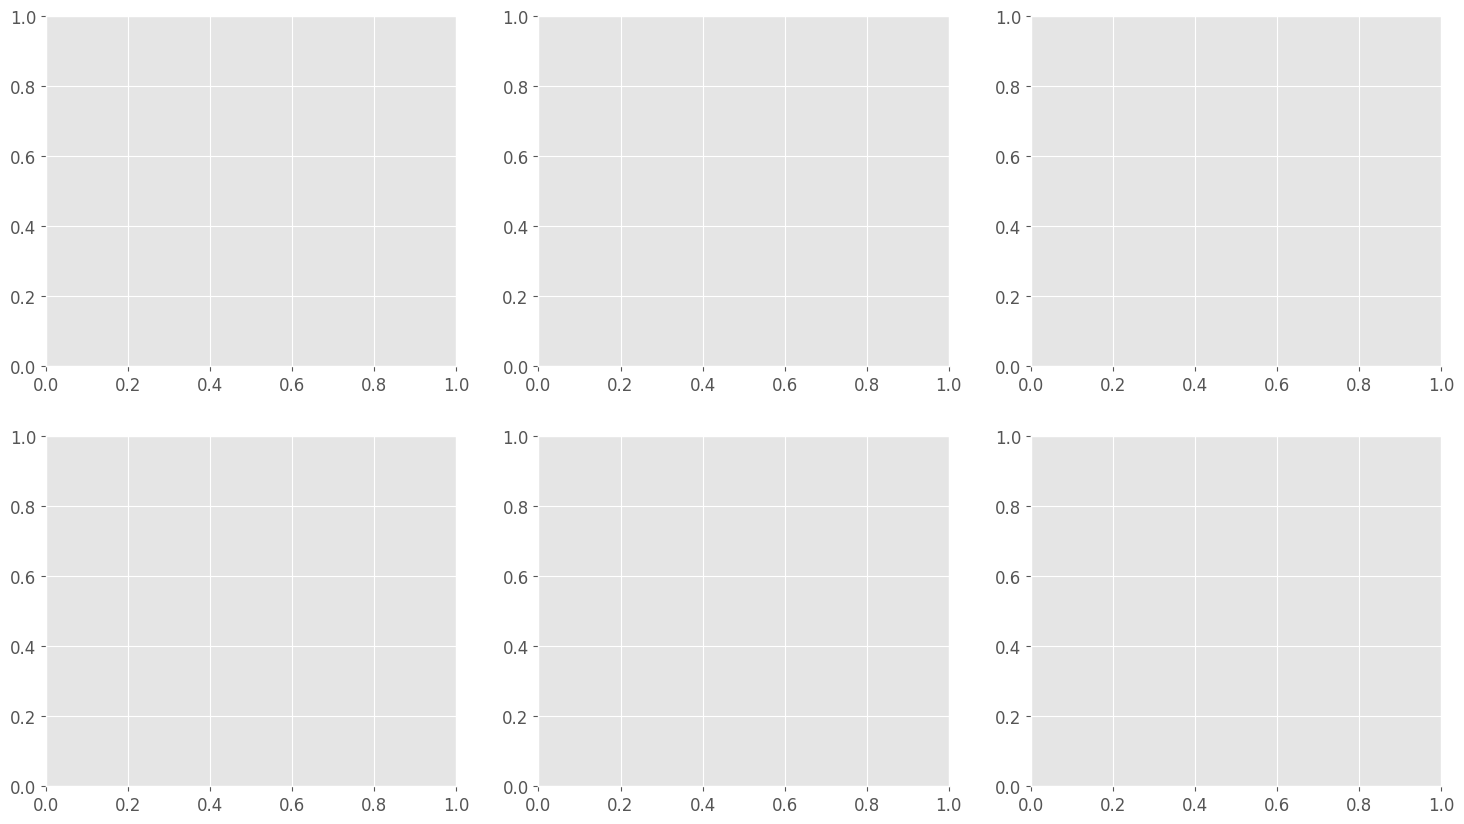

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pathlib import Path

 
 

bias_imgs = [
    "beta_bias_sigma1.png",
    "beta_bias_sigma2.png",
    "beta_bias_sigma3.png",
    "beta_bias_sigma5.png",
    "beta_bias_sigma8.png",
    "beta_bias_sigma10.png"
]
 

corr_imgs = [
    "transport_corr_sigma1.png",
    "transport_corr_sigma2.png",
    "transport_corr_sigma3.png",
    "transport_corr_sigma5.png",
    "transport_corr_sigma8.png",
    "transport_corr_sigma10.png"
]

 

field_imgs = [
    "true_transport_directional.png",
    "true_transport_gaussian.png",
    "true_transport_strong.png",
    "true_transport_weak.png"
]

 

def make_panel_figure(
    image_files,
    output_name,
    ncols=3,
    figsize=(18, 10),
    dpi=600
):
    
    n = len(image_files)
    nrows = int((n + ncols - 1) / ncols)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=figsize
    )

    axes = axes.flatten()

    panel_labels = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")

    for i, img_path in enumerate(image_files):

        img = mpimg.imread(img_path)

        axes[i].imshow(img)

        axes[i].axis("off")

        axes[i].text(
            0.02,
            0.98,
            panel_labels[i],
            transform=axes[i].transAxes,
            fontsize=20,
            fontweight="bold",
            va="top",
            ha="left",
            color="black"
        )

    # remove empty panels
    for j in range(i + 1, len(axes)):
        axes[j].axis("off")

    plt.tight_layout()

    plt.savefig(
        output_name,
        dpi=dpi,
        bbox_inches="tight"
    )

    plt.close()

 

make_panel_figure(
    image_files=bias_imgs,
    output_name="Figure1_BiasPhaseDiagram.png",
    ncols=3,
    figsize=(18, 10),
    dpi=600
)

 

make_panel_figure(
    image_files=corr_imgs,
    output_name="Figure2_TransportCorrelation.png",
    ncols=3,
    figsize=(18, 10),
    dpi=600
)

 

make_panel_figure(
    image_files=field_imgs,
    output_name="Figure3_TransportFields.png",
    ncols=2,
    figsize=(12, 10),
    dpi=600
)

print("All composite figures saved.")

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

 

condition_imgs = [
    "condition_sigma1.png",
    "condition_sigma2.png",
    "condition_sigma3.png",
    "condition_sigma5.png",
    "condition_sigma8.png",
    "condition_sigma10.png"
]

 

fig, axes = plt.subplots(
    2,
    3,
    figsize=(18,10)
)

axes = axes.flatten()

panel_labels = list("ABCDEF")

for i, img_file in enumerate(condition_imgs):

    img = mpimg.imread(img_file)

    axes[i].imshow(img)

    axes[i].axis("off")

    axes[i].text(
        0.02,
        0.98,
        panel_labels[i],
        transform=axes[i].transAxes,
        fontsize=20,
        fontweight="bold",
        va="top",
        ha="left"
    )

plt.tight_layout()

plt.savefig(
    "Figure3_ConditionNumber.png",
    dpi=600,
    bbox_inches="tight"
)

plt.close()

print("Saved Figure3_ConditionNumber.png")